# Solar Filament Segmentation 2026 — Polygon + Exclusive-Instance Experiment

This Kaggle GPU experiment keeps YOLO26s and native 2048 × 2048 inference fixed while changing the two highest-priority pipeline steps: direct COCO polygon labels and confidence-ordered mutually-exclusive prediction masks. Validation sweeps confidence, NMS IoU, minimum instance area, and maximum instances per image against PQ.

Baseline context from the prior run: Kaggle score 0.36; local PQ 0.422 (SQ 0.647, RQ 0.627); TP 1,093, FP 520, FN 724; best confidence 0.25; best mask mAP50–95 0.211 at epoch 92.

This notebook is intended for a Kaggle GPU session and is intentionally left unexecuted in this local workspace. The original notebook is not modified.


## 1. Install dependencies and import libraries

The training configuration uses disk caching rather than a RAM cache. Package installation disables pip's wheel cache to conserve the session disk.

In [1]:
%pip -q install ultralytics pycocotools scikit-learn tqdm torchmetrics threadpoolctl psutil

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 44.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 3.7 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import os
import csv
import gc
import random
import shutil
import time
import warnings
import multiprocessing
from concurrent.futures import ThreadPoolExecutor
from functools import partial

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
try:
    import psutil
except ImportError:
    psutil = None

from pycocotools import mask as mask_utils
from pycocotools.coco import COCO
from sklearn.model_selection import GroupShuffleSplit
from tqdm.auto import tqdm
from torchmetrics.segmentation import DiceScore
from threadpoolctl import threadpool_limits
from ultralytics import YOLO
from ultralytics.data.converter import merge_multi_segment

# Hide standard Python warnings
warnings.filterwarnings("ignore")

# Hide underlying C-level / ctypes environment logs
os.environ["PYTHONWARNINGS"] = "ignore"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CUDA_DEVICE_COUNT = torch.cuda.device_count() if torch.cuda.is_available() else 0
MAX_GPUS_TO_USE = 2
GPU_DEVICE_IDS = list(range(min(CUDA_DEVICE_COUNT, MAX_GPUS_TO_USE)))
GPU_COUNT_USED = len(GPU_DEVICE_IDS)

if GPU_COUNT_USED >= 2:
    TRAIN_DEVICE = GPU_DEVICE_IDS
elif GPU_COUNT_USED == 1:
    TRAIN_DEVICE = GPU_DEVICE_IDS[0]
else:
    TRAIN_DEVICE = "cpu"

# Ultralytics prediction uses one explicit device; distributed training below
# uses both GPUs when they are available.
INFERENCE_DEVICE = GPU_DEVICE_IDS[0] if GPU_COUNT_USED else "cpu"

print(f"Training device(s): {TRAIN_DEVICE}")
print(f"Inference device: {INFERENCE_DEVICE}")
if CUDA_DEVICE_COUNT:
    for gpu_id in GPU_DEVICE_IDS:
        print(f"GPU {gpu_id}: {torch.cuda.get_device_name(gpu_id)}")
    print(f"CUDA devices available: {CUDA_DEVICE_COUNT}; using {GPU_COUNT_USED}")

CPU_COUNT = os.cpu_count() or 1
print(f"Logical CPU count: {CPU_COUNT}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Training device(s): [0, 1]
Inference device: 0
GPU 0: Tesla T4
GPU 1: Tesla T4
CUDA devices available: 2; using 2
Logical CPU count: 4


## 2. Configure paths and experiment

This is an isolated experiment: it writes a new YOLO dataset, training run, metrics, and submission files. It preserves the baseline model family, full-frame image size, and training augmentations so the label and postprocessing changes can be compared cleanly. Run it in Kaggle with GPU enabled; the notebook is not executed on the local machine.


In [3]:
SEED = 42

NUM_EPOCHS = 100

VALIDATION_FRACTION = 0.2
PATIENCE = 10

IMAGE_SIZE = 2048
NUM_WORKERS = 4  # Hard cap for custom CPU worker pools.
WORKER_CPU_THREADS = 1

# In Ultralytics DDP, workers is per GPU rank. Keep the global worker count <= 4.
YOLO_WORKERS_PER_GPU = (
    min(NUM_WORKERS // GPU_COUNT_USED, 4)
    if GPU_COUNT_USED > 0
    else 0
)
BATCH_SIZE = GPU_COUNT_USED if GPU_COUNT_USED > 0 else 1  # One image per GPU.

# One native-resolution image at a time keeps full-size masks bounded.
VAL_BATCH_SIZE = 1
MAX_PENDING_VALIDATION = NUM_WORKERS * 2
MAX_DETECTIONS = 100

RAM_LIMIT_GIB = 30.0
RAM_RESERVE_GIB = 6.0
DISK_LIMIT_GIB = 30.0
DISK_RESERVE_GIB = 10.0  # Preferred reserve; reduced only if the mounted volume requires it.
MIN_DISK_RESERVE_GIB = 4.0
CACHE_SAFETY_FACTOR = 1.25
TRAIN_OUTPUT_RESERVE_GIB = 2.0
GIB = 1024 ** 3
YOLO_CACHE_MODE = "disk"  # Preflight switches this to False if disk cache cannot fit.
ACTIVE_DISK_RESERVE_GIB = DISK_RESERVE_GIB

MIN_INSTANCE_AREA_CANDIDATES = (5, 10, 20, 50, 100, 200)
MAX_INSTANCES_CANDIDATES = (5, 8, 10, 12, 15, None)
NMS_IOU_CANDIDATES = (0.50, 0.60, 0.70, 0.80, 0.90)
YOLO_MODEL_NAME = "yolo26s-seg.pt"

YOLO_DATA_DIR = Path.cwd() / "yolo_filament_dataset_polygon_direct"
RUNS_DIR = Path.cwd() / "yolo_runs"
RUN_NAME = "yolo26s_polygon_direct_exclusive_instances"
DATA_YAML = YOLO_DATA_DIR / "filament.yaml"

SUBMISSION_PATH = Path.cwd() / "solar_filament_yolo26s_polygon_exclusive_submission.csv"
FINAL_METRICS_PATH = Path.cwd() / "solar_filament_yolo26s_polygon_exclusive_validation_metrics.csv"
PER_IMAGE_METRICS_PATH = Path.cwd() / "solar_filament_yolo26s_polygon_exclusive_per_image_metrics.csv"

REBUILD_YOLO_DATASET = True
CREATE_SUBMISSION = True

CONFIDENCE_CANDIDATES = (0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60)
PQ_MATCH_IOU = 0.50


def _read_cgroup_memory_pair(limit_path, current_path):
    try:
        limit_text = Path(limit_path).read_text().strip()
        current_text = Path(current_path).read_text().strip()
        if limit_text == "max":
            return None
        limit_bytes = int(limit_text)
        current_bytes = int(current_text)
        if limit_bytes >= (1 << 60):  # cgroup v1 unlimited sentinel
            return None
        return max(0, limit_bytes - current_bytes)
    except (OSError, ValueError):
        return None


def available_ram_bytes():
    for limit_path, current_path in (
        ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory.current"),
        ("/sys/fs/cgroup/memory/memory.limit_in_bytes", "/sys/fs/cgroup/memory/memory.usage_in_bytes"),
    ):
        available = _read_cgroup_memory_pair(limit_path, current_path)
        if available is not None:
            return available
    if psutil is not None:
        try:
            return int(psutil.virtual_memory().available)
        except Exception:
            pass
    return None


def require_ram_headroom(stage, minimum_gib):
    available = available_ram_bytes()
    if available is None:
        print(f"[RAM] Could not read a runtime memory limit before {stage}; using bounded batches/workers.")
        return
    available_gib = available / GIB
    print(f"[RAM] Available before {stage}: {available_gib:.1f} GiB")
    if available_gib < minimum_gib:
        raise MemoryError(
            f"Only {available_gib:.1f} GiB RAM is available before {stage}; "
            f"need at least {minimum_gib:.1f} GiB to preserve headroom under the "
            f"{RAM_LIMIT_GIB:.1f} GiB session limit. Free memory or restart the session."
        )


def directory_size_bytes(root):
    root = Path(root)
    if not root.exists():
        return 0
    total = 0
    for item in root.rglob("*"):
        if item.is_file() and not item.is_symlink():
            try:
                total += item.stat().st_size
            except OSError:
                pass
    return total


def preflight_training_resources(train_split, val_split, image_dir):
    global YOLO_CACHE_MODE, ACTIVE_DISK_RESERVE_GIB

    require_ram_headroom("dataset preparation", minimum_gib=RAM_RESERVE_GIB + 2.0)
    records = pd.concat([train_split, val_split], ignore_index=True)

    # Conservative cache estimate: RGB uint8 array per YOLO record at full size.
    estimated_cache_bytes = int(
        len(records) * IMAGE_SIZE * IMAGE_SIZE * 3 * CACHE_SAFETY_FACTOR
    )
    # Copies are only used if symlink creation is unavailable; count duplicate records too.
    copy_bytes = 0
    for file_name in records["file_name"]:
        source = Path(image_dir) / file_name
        if source.is_file():
            copy_bytes += source.stat().st_size

    output_reserve = int(TRAIN_OUTPUT_RESERVE_GIB * GIB)
    workspace_bytes = directory_size_bytes(Path.cwd())
    disk = shutil.disk_usage(YOLO_DATA_DIR.parent)
    effective_budget_bytes = min(int(DISK_LIMIT_GIB * GIB), int(disk.total))

    # Prefer disk caching with the full reserve. If the mounted filesystem is
    # smaller than the advertised session quota, turn caching off (never RAM-on)
    # and only reduce the reserve as far as 4 GiB.
    cache_options = (("disk", estimated_cache_bytes), (False, 0))
    reserve_options = [
        value for value in (DISK_RESERVE_GIB, 8.0, 6.0, MIN_DISK_RESERVE_GIB)
        if value <= DISK_RESERVE_GIB
    ]
    selected_plan = None

    for cache_mode, cache_bytes in cache_options:
        for reserve_gib in reserve_options:
            reserve_bytes = int(reserve_gib * GIB)
            planned_new_bytes = cache_bytes + copy_bytes + output_reserve + reserve_bytes
            if (
                planned_new_bytes <= effective_budget_bytes
                and workspace_bytes + planned_new_bytes <= effective_budget_bytes
                and disk.free >= planned_new_bytes
            ):
                selected_plan = (cache_mode, reserve_gib, planned_new_bytes, cache_bytes)
                break
        if selected_plan is not None:
            break

    if selected_plan is None:
        no_cache_minimum = (
            copy_bytes
            + output_reserve
            + int(MIN_DISK_RESERVE_GIB * GIB)
        )
        raise OSError(
            "Insufficient writable disk even with YOLO image caching disabled. "
            f"Filesystem capacity: {disk.total / GIB:.1f} GiB; free: {disk.free / GIB:.1f} GiB; "
            f"workspace: {workspace_bytes / GIB:.1f} GiB; minimum planned use: "
            f"{no_cache_minimum / GIB:.1f} GiB (includes a {MIN_DISK_RESERVE_GIB:.1f} GiB reserve). "
            "Free disk space or select a larger working volume."
        )

    YOLO_CACHE_MODE, ACTIVE_DISK_RESERVE_GIB, planned_new_bytes, cache_bytes = selected_plan
    print(
        f"[DISK] Cache mode: {YOLO_CACHE_MODE}; estimated cache: {cache_bytes / GIB:.1f} GiB; "
        f"worst-case image copies: {copy_bytes / GIB:.2f} GiB."
    )
    print(
        f"[DISK] Planned additional use: {planned_new_bytes / GIB:.1f} GiB; "
        f"reserved free space: {ACTIVE_DISK_RESERVE_GIB:.1f} GiB; "
        f"filesystem free: {disk.free / GIB:.1f} GiB."
    )
    if YOLO_CACHE_MODE is False:
        print("[DISK] Full-resolution training will continue without image caching; RAM caching is disabled.")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def configure_main_process_threads():
    cv2.setNumThreads(WORKER_CPU_THREADS)
    try:
        torch.set_num_threads(WORKER_CPU_THREADS)
    except RuntimeError:
        pass


configure_main_process_threads()
set_seed()

# --- Logging Framework Configurations ---
print(f"Random seed initialization: {SEED}")
print(f"Split ratio: Train = {1.0 - VALIDATION_FRACTION:.2f} / Validation = {VALIDATION_FRACTION:.2f}")
print(f"Training epochs: {NUM_EPOCHS} (Early stopping patience: {PATIENCE})")
print(f"Input size: {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Custom CPU worker cap: {NUM_WORKERS}")
print(f"YOLO data workers per GPU: {YOLO_WORKERS_PER_GPU}")
print(f"YOLO global batch size: {BATCH_SIZE}")
print(f"Inference batch size: {VAL_BATCH_SIZE}")
print("Image cache mode: selected by disk preflight; RAM caching is disabled.")

Random seed initialization: 42
Split ratio: Train = 0.80 / Validation = 0.20
Training epochs: 100 (Early stopping patience: 10)
Input size: 2048 x 2048
Custom CPU worker cap: 4
YOLO data workers per GPU: 2
YOLO global batch size: 2
Inference batch size: 1
Image cache mode: selected by disk preflight; RAM caching is disabled.


In [4]:
def find_dataset_root():
    expected = "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
    candidates = [Path.cwd(), Path.cwd().parent, Path("/kaggle/input")]

    for parent in candidates:
        if not parent.exists():
            continue

        for annotation in parent.glob("**/" + expected):
            root = annotation.parent.parent
            if (root / "train" / "train_images").is_dir() and (root / "test" / "test_images").is_dir():
                return root

    raise FileNotFoundError("Could not find MAGFiLO_1.0_Kaggle_2026 with train and test image folders.")

DATA_ROOT = find_dataset_root()
TRAIN_DIR = DATA_ROOT / "train"
TRAIN_IMAGE_DIR = TRAIN_DIR / "train_images"
TEST_IMAGE_DIR = DATA_ROOT / "test" / "test_images"
ANNOTATION_PATH = TRAIN_DIR / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"

print(f"Dataset root: {DATA_ROOT}")
print(f"Annotation JSON: {ANNOTATION_PATH}")
print(f"YOLO model: {YOLO_MODEL_NAME}")
print(f"Image size: {IMAGE_SIZE}")
print(f"Global training batch: {BATCH_SIZE} ({YOLO_WORKERS_PER_GPU} workers per GPU)")
print(f"Validation fraction: {VALIDATION_FRACTION:.0%}")
print(f"PQ matching IoU threshold: {PQ_MATCH_IOU:.2f}")

Dataset root: /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026
Annotation JSON: /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json
YOLO model: yolo26s-seg.pt
Image size: 2048
Global training batch: 2 (2 workers per GPU)
Validation fraction: 20%
PQ matching IoU threshold: 0.50


## 3. Load annotations and create a leakage-safe split

The split is performed using the physical filename rather than the COCO record ID. Multiple annotation records for the same JPEG remain on one side of the split.

In [5]:
coco = COCO(str(ANNOTATION_PATH))
image_ids = list(coco.imgs.keys())
records = pd.DataFrame([{"image_id": image_id, "file_name": coco.imgs[image_id]["file_name"]} for image_id in image_ids])

splitter = GroupShuffleSplit(n_splits=1, test_size=VALIDATION_FRACTION, random_state=SEED)
train_idx, val_idx = next(splitter.split(records, groups=records["file_name"]))

train_records = records.iloc[train_idx].reset_index(drop=True)
val_records = records.iloc[val_idx].reset_index(drop=True)

train_files = set(train_records["file_name"])
val_files = set(val_records["file_name"])

assert train_files.isdisjoint(val_files), "A physical image appears in both splits."

print(f"Training records: {len(train_records):,} across {len(train_files):,} physical images")
print(f"Validation records: {len(val_records):,} across {len(val_files):,} physical images")
print(f"Train/validation filename overlap: {len(train_files & val_files)}")

loading annotations into memory...
Done (t=0.78s)
creating index...
index created!
Training records: 922 across 565 physical images
Validation records: 232 across 142 physical images
Train/validation filename overlap: 0


## 3a. Inspect repeated physical images

Some physical JPEGs appear in multiple COCO image records. This diagnostic compares their record-level mask unions and displays several overlays. It does not merge or discard any annotation records.


Physical JPEGs with multiple COCO records: 296
Records belonging to duplicate JPEGs: 743


,file_name,image_ids,record_count
0,20110128174814Mh.jpeg,"[010402-20110128174814Mh, 010401-2011012817481...",3
1,20110203082634Lh.jpeg,"[010102-20110203082634Lh, 010101-2011020308263...",3
2,20110215083814Th.jpeg,"[010401-20110215083814Th, 010402-2011021508381...",3
3,20110301082654Uh.jpeg,"[010403-20110301082654Uh, 010401-2011030108265...",3
4,20110306082634Lh.jpeg,"[010403-20110306082634Lh, 010401-2011030608263...",3
5,20110322005814Mh.jpeg,"[050101-20110322005814Mh, 050102-2011032200581...",3
6,20110410141654Bh.jpeg,"[010403-20110410141654Bh, 010401-2011041014165...",3
7,20110429135554Bh.jpeg,"[050102-20110429135554Bh, 050103-2011042913555...",3
8,20110502063154Uh.jpeg,"[050101-20110502063154Uh, 050102-2011050206315...",3
9,20110517164514Mh.jpeg,"[050103-20110517164514Mh, 050102-2011051716451...",3


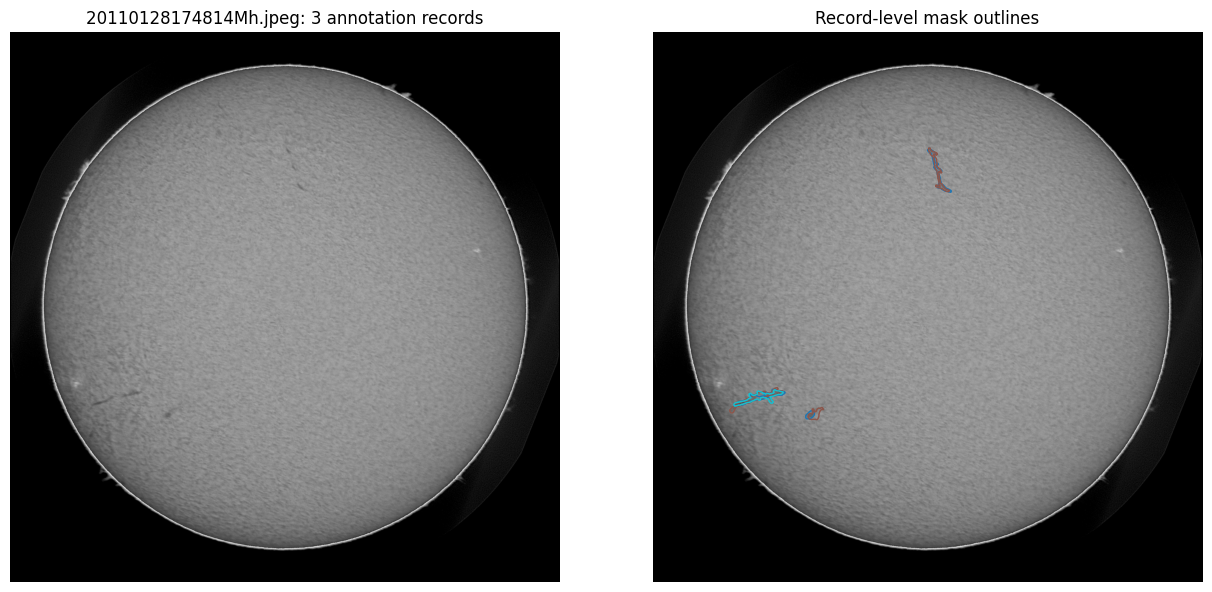

Record IDs: ['010402-20110128174814Mh', '010401-20110128174814Mh', '010403-20110128174814Mh']


,010402-20110128174814Mh,010401-20110128174814Mh,010403-20110128174814Mh
010402-20110128174814Mh,1.000,0.504,0.345
010401-20110128174814Mh,0.504,1.000,0.324
010403-20110128174814Mh,0.345,0.324,1.000


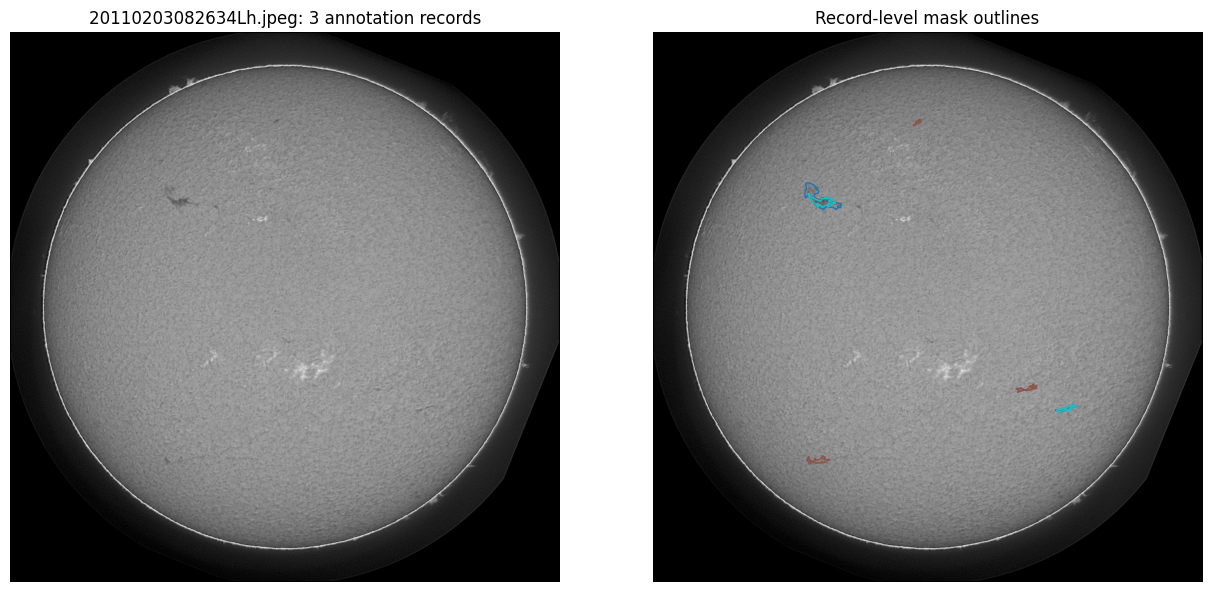

Record IDs: ['010102-20110203082634Lh', '010101-20110203082634Lh', '010103-20110203082634Lh']


,010102-20110203082634Lh,010101-20110203082634Lh,010103-20110203082634Lh
010102-20110203082634Lh,1.000,0.248,0.308
010101-20110203082634Lh,0.248,1.000,0.443
010103-20110203082634Lh,0.308,0.443,1.000


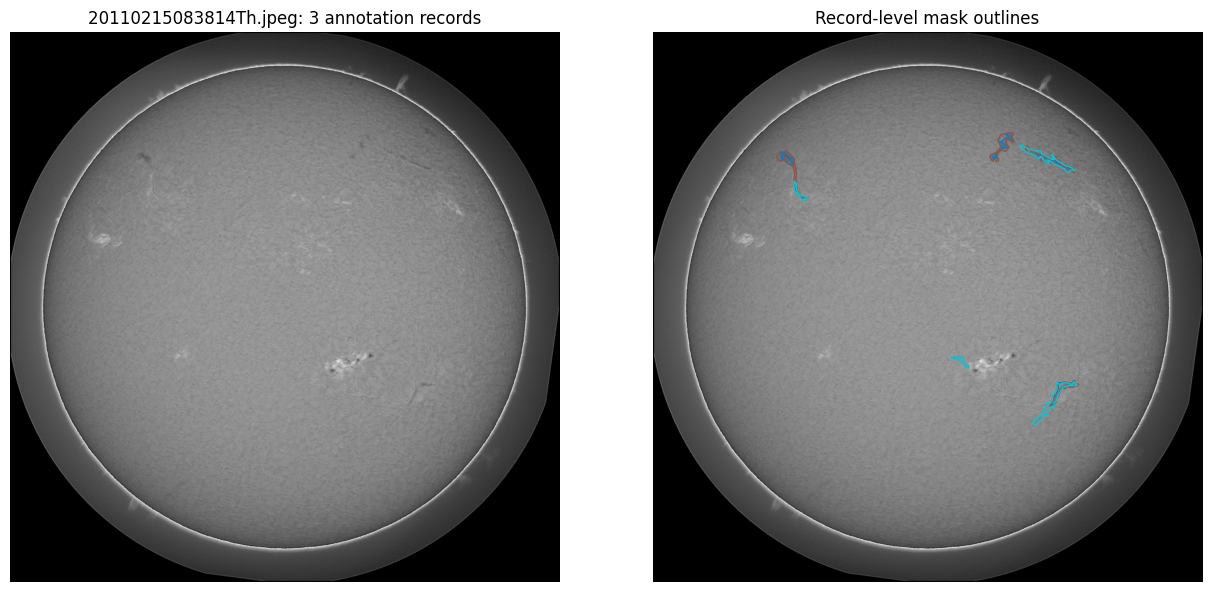

Record IDs: ['010401-20110215083814Th', '010402-20110215083814Th', '010403-20110215083814Th']


,010401-20110215083814Th,010402-20110215083814Th,010403-20110215083814Th
010401-20110215083814Th,1.000,0.454,0.279
010402-20110215083814Th,0.454,1.000,0.323
010403-20110215083814Th,0.279,0.323,1.000


In [6]:
duplicate_groups = (
    records.groupby("file_name")["image_id"]
    .agg(list)
    .loc[lambda values: values.str.len() > 1]
)
duplicate_summary = pd.DataFrame(
    {
        "file_name": duplicate_groups.index,
        "image_ids": duplicate_groups.values,
        "record_count": duplicate_groups.map(len).values,
    }
).sort_values(["record_count", "file_name"], ascending=[False, True]).reset_index(drop=True)

print(f"Physical JPEGs with multiple COCO records: {len(duplicate_summary):,}")
print(
    f"Records belonging to duplicate JPEGs: "
    f"{int(duplicate_summary['record_count'].sum()):,}"
)
display(duplicate_summary.head(12))

def record_union_mask(image_id, shape):
    mask = np.zeros(shape, dtype=bool)
    for annotation in coco.loadAnns(coco.getAnnIds(imgIds=[image_id])):
        mask |= coco.annToMask(annotation).astype(bool)
    return mask

for _, duplicate in duplicate_summary.head(3).iterrows():
    file_name = duplicate["file_name"]
    image = cv2.imread(str(TRAIN_IMAGE_DIR / file_name), cv2.IMREAD_GRAYSCALE)
    if image is None:
        print(f"[WARNING] Could not read duplicate image: {file_name}")
        continue

    image_ids_for_file = duplicate["image_ids"]
    record_masks = [
        record_union_mask(image_id, image.shape)
        for image_id in image_ids_for_file
    ]

    pairwise_iou = np.eye(len(record_masks), dtype=np.float32)
    for left in range(len(record_masks)):
        for right in range(left + 1, len(record_masks)):
            intersection = int(np.logical_and(record_masks[left], record_masks[right]).sum())
            union = int(np.logical_or(record_masks[left], record_masks[right]).sum())
            value = intersection / union if union else 1.0
            pairwise_iou[left, right] = pairwise_iou[right, left] = value

    fig, axes = plt.subplots(1, 2, figsize=(13, 6))
    axes[0].imshow(image, cmap="gray")
    axes[0].set_title(f"{file_name}: {len(record_masks)} annotation records")

    axes[1].imshow(image, cmap="gray")
    colors = plt.cm.tab10(np.linspace(0, 1, max(1, len(record_masks))))
    for record_index, mask in enumerate(record_masks):
        if mask.any():
            axes[1].contour(
                mask.astype(np.uint8),
                levels=[0.5],
                colors=[colors[record_index]],
                linewidths=1.0,
            )
    axes[1].set_title("Record-level mask outlines")
    for axis in axes:
        axis.axis("off")
    fig.tight_layout()
    plt.show()

    print(f"Record IDs: {image_ids_for_file}")
    display(pd.DataFrame(pairwise_iou, index=image_ids_for_file, columns=image_ids_for_file).round(3))


## 4. Build the YOLO segmentation dataset

Each COCO polygon is normalized directly into the YOLO segmentation label, without converting it through a raster mask and contour extraction. This experiment keeps every valid polygon instance and does not apply a training-label area cutoff. JPEGs are linked where possible; the existing disk preflight remains in place.


In [7]:
def configure_worker_process():
    cv2.setNumThreads(WORKER_CPU_THREADS)
    try:
        torch.set_num_threads(WORKER_CPU_THREADS)
    except RuntimeError:
        pass
    try:
        torch.set_num_interop_threads(WORKER_CPU_THREADS)
    except RuntimeError:
        pass
    try:
        threadpool_limits(limits=WORKER_CPU_THREADS)
    except Exception:
        pass

    if hasattr(os, "sched_getaffinity"):
        available_cpus = sorted(os.sched_getaffinity(0))
        if available_cpus:
            identity = multiprocessing.current_process()._identity
            worker_index = identity[0] - 1 if identity else 0
            cpu = available_cpus[worker_index % len(available_cpus)]
            if hasattr(os, "sched_setaffinity"):
                os.sched_setaffinity(0, {cpu})


def coco_polygons_to_yolo_points(annotation, width, height):
    """Normalize original COCO polygon coordinates without rasterizing masks."""
    segmentation = annotation.get("segmentation")

    if isinstance(segmentation, dict):
        raise ValueError(
            f"Annotation {annotation.get('id')} uses RLE segmentation. "
            "This experiment expects the competition's polygon annotations."
        )
    if not isinstance(segmentation, list) or not segmentation:
        return None

    polygons = []
    for raw_polygon in segmentation:
        coordinates = np.asarray(raw_polygon, dtype=np.float32)
        if coordinates.size < 6 or coordinates.size % 2:
            continue
        points = coordinates.reshape(-1, 2)
        if not np.isfinite(points).all():
            raise ValueError(f"Non-finite polygon coordinates in annotation {annotation.get('id')}")
        if len(points) >= 3:
            polygons.append(points)

    if not polygons:
        return None

    # YOLO stores one polygon per instance row. If a COCO annotation has
    # multiple disconnected rings, use Ultralytics' polygon-joining routine.
    if len(polygons) == 1:
        points = polygons[0].copy()
    else:
        joined = merge_multi_segment(polygons)
        points = np.concatenate(joined, axis=0).astype(np.float32)

    points[:, 0] /= float(width)
    points[:, 1] /= float(height)
    points = np.clip(points, 0.0, 1.0)

    if len(points) < 3:
        return None
    if np.ptp(points[:, 0]) <= 1e-8 or np.ptp(points[:, 1]) <= 1e-8:
        return None

    return points


def worker_process_record(row_dict, annotation_path_str, train_image_dir_str, image_dir_str, label_dir_str):
    global _local_coco
    configure_worker_process()

    if "_local_coco" not in globals():
        import sys
        old_stdout = sys.stdout
        devnull = open(os.devnull, "w")
        try:
            sys.stdout = devnull
            _local_coco = COCO(annotation_path_str)
        finally:
            sys.stdout = old_stdout
            devnull.close()

    train_img_dir = Path(train_image_dir_str)
    img_out_dir = Path(image_dir_str)
    lbl_out_dir = Path(label_dir_str)

    image_id = row_dict["image_id"]
    file_name = row_dict["file_name"]
    source_path = train_img_dir / file_name

    if not source_path.is_file():
        return 0

    source_stem = Path(file_name).stem
    sample_stem = f"{image_id}_{source_stem}"
    image_path = img_out_dir / f"{sample_stem}{source_path.suffix}"
    label_path = lbl_out_dir / f"{sample_stem}.txt"

    image_path.parent.mkdir(parents=True, exist_ok=True)
    if image_path.exists() or image_path.is_symlink():
        image_path.unlink()

    try:
        image_path.symlink_to(source_path.resolve())
    except OSError:
        shutil.copy2(source_path, image_path)

    image_info = _local_coco.imgs[image_id]
    width = int(image_info["width"])
    height = int(image_info["height"])
    annotations = _local_coco.loadAnns(_local_coco.getAnnIds(imgIds=[image_id]))
    lines = []

    for annotation in annotations:
        points = coco_polygons_to_yolo_points(annotation, width, height)
        if points is None:
            continue
        values = ["0"]
        values.extend(f"{value:.7f}" for value in points.reshape(-1))
        lines.append(" ".join(values))

    label_path.write_text("\n".join(lines) + ("\n" if lines else ""), encoding="utf-8")
    return len(lines)


def write_yolo_split_parallel(split_records, split_name):
    print(f"\n[START] Building YOLO split: '{split_name}'", flush=True)
    image_dir = YOLO_DATA_DIR / "images" / split_name
    label_dir = YOLO_DATA_DIR / "labels" / split_name

    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    records_list = split_records[["image_id", "file_name"]].to_dict(orient="records")
    worker_task = partial(
        worker_process_record,
        annotation_path_str=str(ANNOTATION_PATH),
        train_image_dir_str=str(TRAIN_IMAGE_DIR),
        image_dir_str=str(image_dir),
        label_dir_str=str(label_dir),
    )

    empty_labels = 0
    total_instances = 0

    with multiprocessing.Pool(processes=NUM_WORKERS, initializer=configure_worker_process) as pool:
        results = tqdm(
            pool.imap_unordered(worker_task, records_list, chunksize=4),
            total=len(records_list),
            desc=f"Preparing YOLO {split_name}",
        )

        for idx, instance_count in enumerate(results, start=1):
            total_instances += instance_count
            if instance_count == 0:
                empty_labels += 1

            if idx == 1 or idx % 100 == 0 or idx == len(records_list):
                print(
                    f"[{split_name.upper()} Pre-Processing] {idx:,}/{len(records_list):,} "
                    f"| polygon instances: {total_instances:,} | empty: {empty_labels:,}",
                    flush=True,
                )

    print(
        f"[FINISHED] {split_name}: {len(records_list):,} records | "
        f"{total_instances:,} polygon instances | empty labels: {empty_labels:,}\n",
        flush=True,
    )


if REBUILD_YOLO_DATASET and YOLO_DATA_DIR.exists():
    print(f"[CLEANUP] Removing old experiment directory: {YOLO_DATA_DIR}", flush=True)
    shutil.rmtree(YOLO_DATA_DIR)

preflight_training_resources(train_records, val_records, TRAIN_IMAGE_DIR)
write_yolo_split_parallel(train_records, "train")
write_yolo_split_parallel(val_records, "val")

DATA_YAML.write_text(
    f"path: '{YOLO_DATA_DIR.as_posix()}'\n"
    "train: images/train\n"
    "val: images/val\n"
    "names:\n"
    "  0: filament\n",
    encoding="utf-8",
)

print(f"YOLO dataset configuration: {DATA_YAML}")
print(DATA_YAML.read_text())


[RAM] Available before dataset preparation: 27.6 GiB
[DISK] Cache mode: False; estimated cache: 0.0 GiB; worst-case image copies: 0.85 GiB.
[DISK] Planned additional use: 12.8 GiB; reserved free space: 10.0 GiB; filesystem free: 19.5 GiB.
[DISK] Full-resolution training will continue without image caching; RAM caching is disabled.

[START] Building YOLO split: 'train'


Preparing YOLO train:   0%|          | 0/922 [00:00<?, ?it/s]

[TRAIN Pre-Processing] 1/922 | polygon instances: 3 | empty: 0
[TRAIN Pre-Processing] 100/922 | polygon instances: 614 | empty: 0
[TRAIN Pre-Processing] 200/922 | polygon instances: 1,281 | empty: 0
[TRAIN Pre-Processing] 300/922 | polygon instances: 2,037 | empty: 0
[TRAIN Pre-Processing] 400/922 | polygon instances: 2,825 | empty: 0
[TRAIN Pre-Processing] 500/922 | polygon instances: 3,446 | empty: 0
[TRAIN Pre-Processing] 600/922 | polygon instances: 4,149 | empty: 0
[TRAIN Pre-Processing] 700/922 | polygon instances: 4,849 | empty: 0
[TRAIN Pre-Processing] 800/922 | polygon instances: 5,523 | empty: 0
[TRAIN Pre-Processing] 900/922 | polygon instances: 6,211 | empty: 0
[TRAIN Pre-Processing] 922/922 | polygon instances: 6,382 | empty: 0
[FINISHED] train: 922 records | 6,382 polygon instances | empty labels: 0


[START] Building YOLO split: 'val'


Preparing YOLO val:   0%|          | 0/232 [00:00<?, ?it/s]

[VAL Pre-Processing] 1/232 | polygon instances: 10 | empty: 0
[VAL Pre-Processing] 100/232 | polygon instances: 828 | empty: 0
[VAL Pre-Processing] 200/232 | polygon instances: 1,600 | empty: 0
[VAL Pre-Processing] 232/232 | polygon instances: 1,817 | empty: 0
[FINISHED] val: 232 records | 1,817 polygon instances | empty labels: 0

YOLO dataset configuration: /kaggle/working/yolo_filament_dataset_polygon_direct/filament.yaml
path: '/kaggle/working/yolo_filament_dataset_polygon_direct'
train: images/train
val: images/val
names:
  0: filament



## 5. Train YOLO26s-seg at full resolution

Training uses both available GPUs with a global batch of 2 (one 2048 x 2048 image per T4). Data loading uses two workers per GPU, four total. Disk caching is enabled only when the actual working volume can fit the estimated cache and reserve. If it cannot, caching is disabled (never switched to RAM).

In [8]:
print("Building pretrained YOLO26s segmentation model...")
model = YOLO(YOLO_MODEL_NAME)

require_ram_headroom("training", minimum_gib=RAM_RESERVE_GIB + 6.0)
training_start = time.perf_counter()

train_results = model.train(
    data=str(DATA_YAML),
    epochs=NUM_EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=TRAIN_DEVICE,
    workers=YOLO_WORKERS_PER_GPU,
    cache=YOLO_CACHE_MODE,
    max_det=MAX_DETECTIONS,
    patience=PATIENCE,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=True,
    pretrained=True,
    
    # --- OPTIMIZER SETTINGS ---
    optimizer="AdamW",     
    lr0=0.0005,            # OPTIMIZED: Slightly lower initial LR for fine-tuning complex textures
    lrf=0.01,              # Final learning rate drops linearly to 1% of lr0
    cos_lr=True, 
    weight_decay=0.05,     # ADDED: Stronger regularization to prevent overfitting on the 707 base images
    amp=(DEVICE.type == "cuda"),
    seed=SEED,
    deterministic=True,
    
    # --- SPATIAL AUGMENTATIONS (High Rotation/Scale Invariance) ---
    fliplr=0.5,            # Standard horizontal flip
    flipud=0.5,            # OPTIMIZED: Vertical flip is completely valid for full-disk solar imagery
    degrees=180.0,         # OPTIMIZED: Full 360-degree rotation invariance (solar filaments can face any direction)
    translate=0.1,         # OPTIMIZED: Allow slight translation shifts
    scale=0.3,             # OPTIMIZED: Zoom in/out to handle varied filament lengths
    shear=0.0,
    perspective=0.0,
    
    # --- COLOR/INTENSITY AUGMENTATIONS (Turned OFF for Physics-Based H-Alpha Data) ---
    hsv_h=0.0,             # DISABLED: No color hue shifts for grayscale/monochromatic H-alpha data
    hsv_s=0.0,             # DISABLED: No saturation shifts
    hsv_v=0.0,             # OPTIMIZED: Set to 0.0 to preserve true physical intensity levels of solar features
    
    # --- CONTEXT AUGMENTATIONS (Tuned for Panoptic Quality / Small Artifacts) ---
    mosaic=0.5,            # OPTIMIZED: Keep at 0.5 to force the network to isolate multiple fragmented filaments
    mixup=0.0,             # DISABLED: Avoids ghosting artifacts on scientific data
    copy_paste=0.0,        
    
    plots=True,
    verbose=True,
)



training_time = time.perf_counter() - training_start

try:
    run_dir = Path(model.trainer.save_dir)
except AttributeError:
    run_dir = RUNS_DIR / RUN_NAME

best_checkpoint = run_dir / "weights" / "best.pt"
if not best_checkpoint.is_file():
    raise FileNotFoundError(f"Best checkpoint was not created: {best_checkpoint}")

del train_results
try:
    del model
except NameError:
    pass
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

model = YOLO(str(best_checkpoint))

print(f"\n[SUCCESS] Training complete!\nRun directory: {run_dir}\nBest checkpoint: {best_checkpoint}\nTraining time: {training_time / 60:.1f} min", flush=True)

Building pretrained YOLO26s segmentation model...
[RAM] Available before training: 27.6 GiB
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/yolo_filament_dataset_polygon_direct/filament.yaml, degrees=180.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=2048, iou=0.7, kobj=1.0, 

## Show Training History

Loading generated artifact visuals from: /kaggle/working/yolo_runs/yolo26s_polygon_direct_exclusive_instances

▶ Displaying Group: Overall Performance & Loss Tracking
----------------------------------------------------------------------


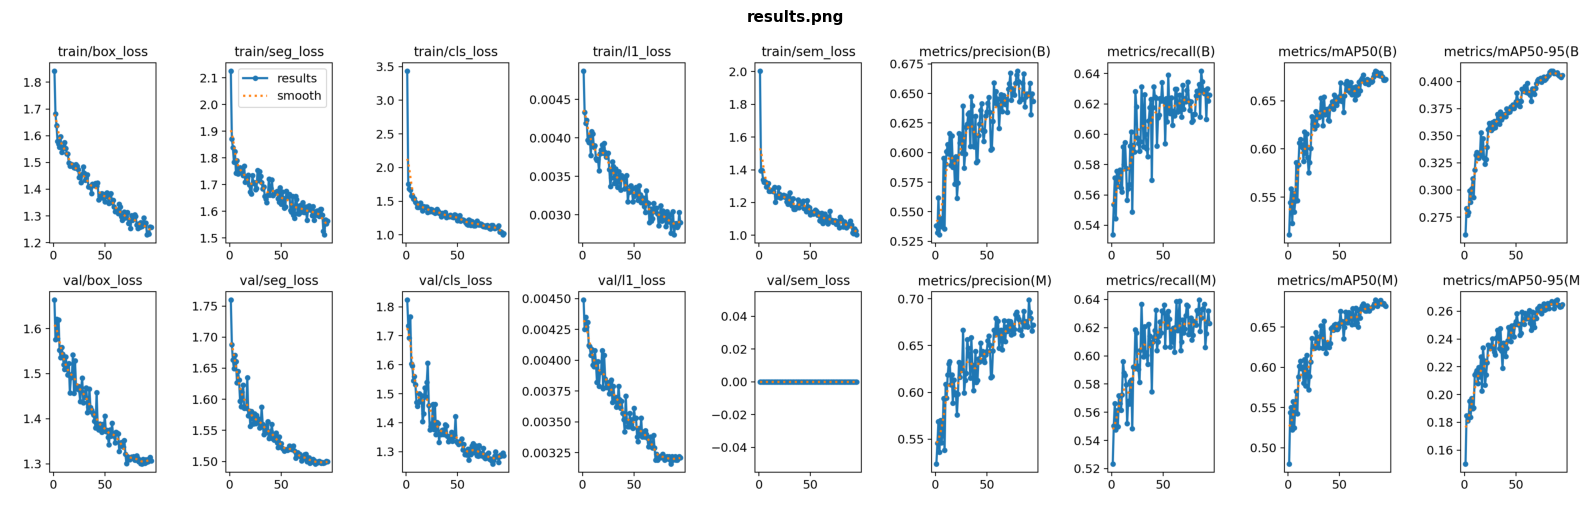


▶ Displaying Group: Bounding Box Localization Metrics
----------------------------------------------------------------------


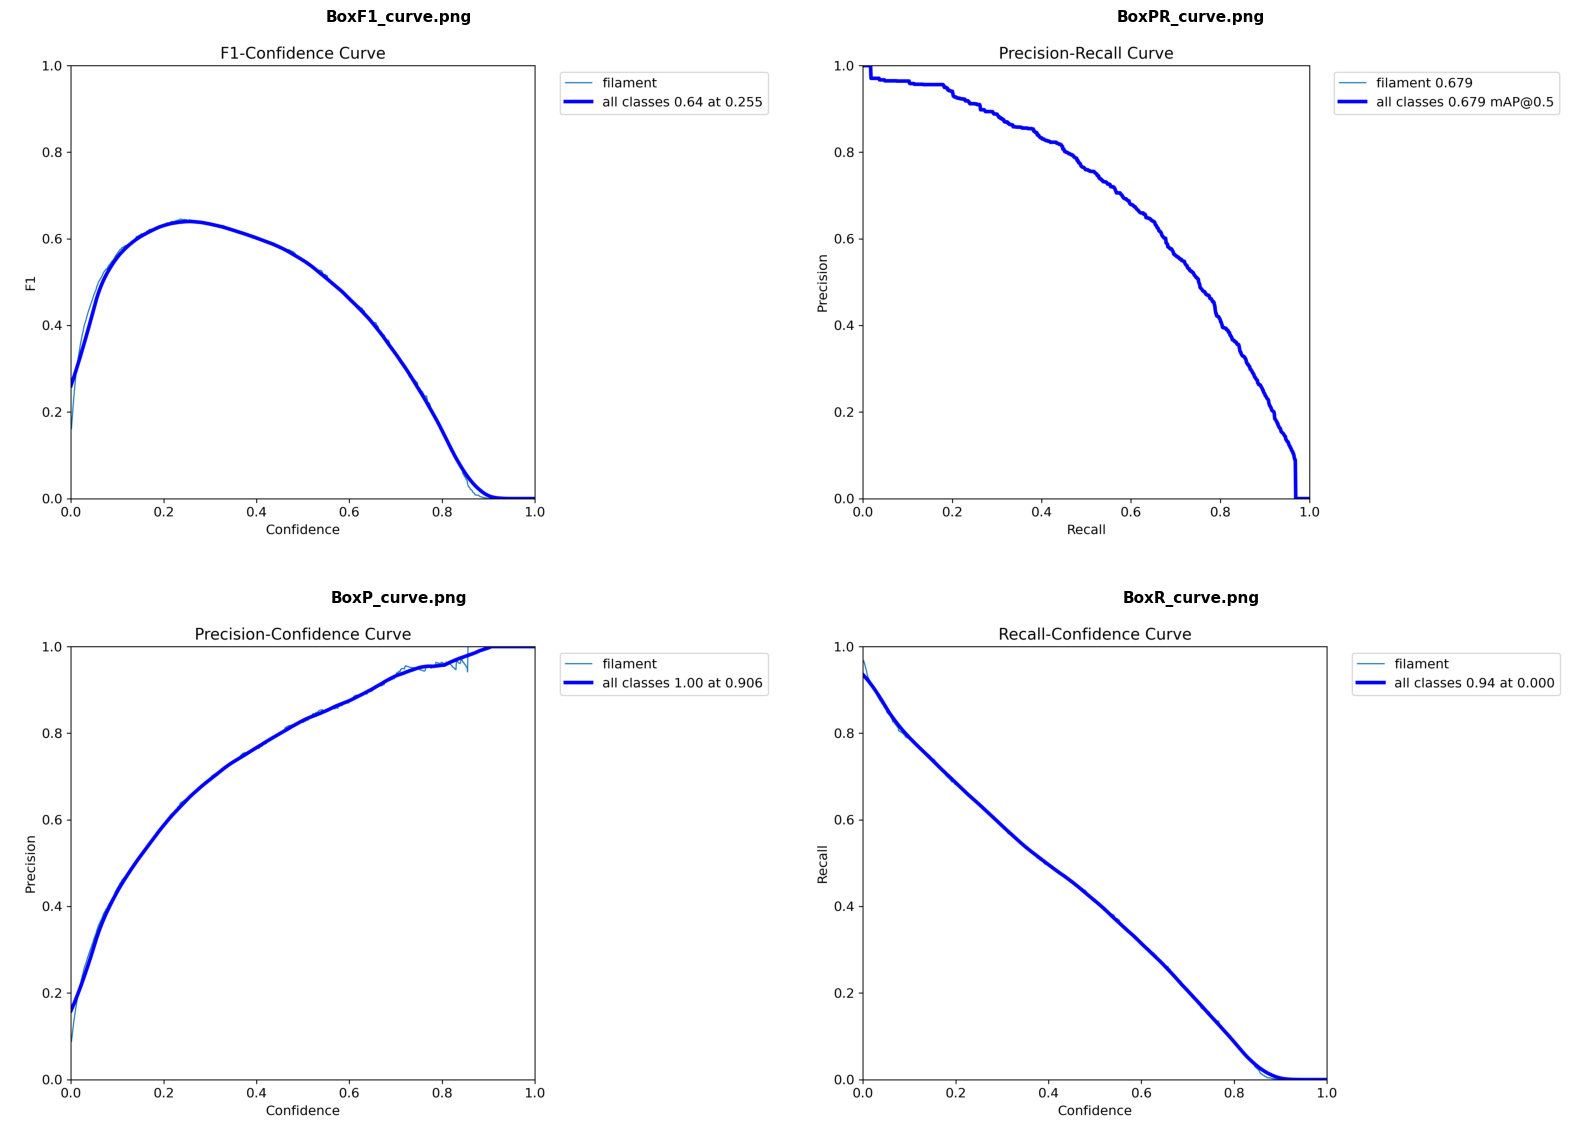


▶ Displaying Group: Instance Segmentation Mask Metrics
----------------------------------------------------------------------


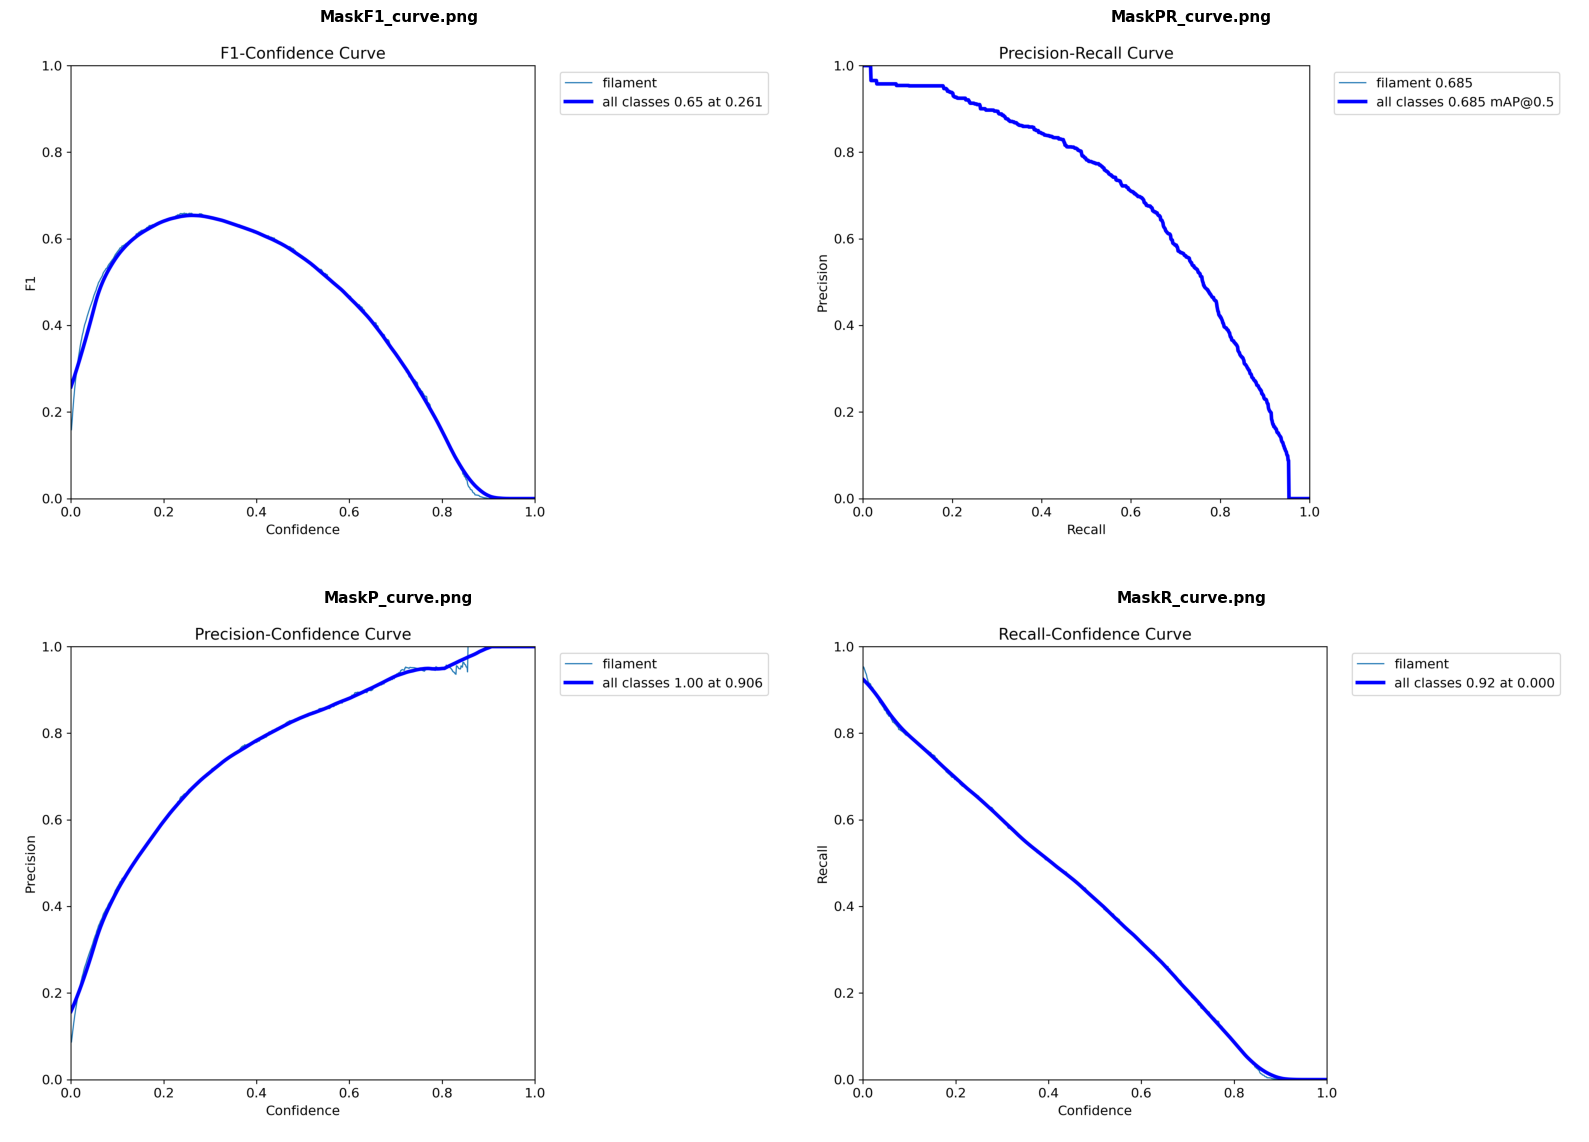


▶ Displaying Group: Confusion Matrices
----------------------------------------------------------------------


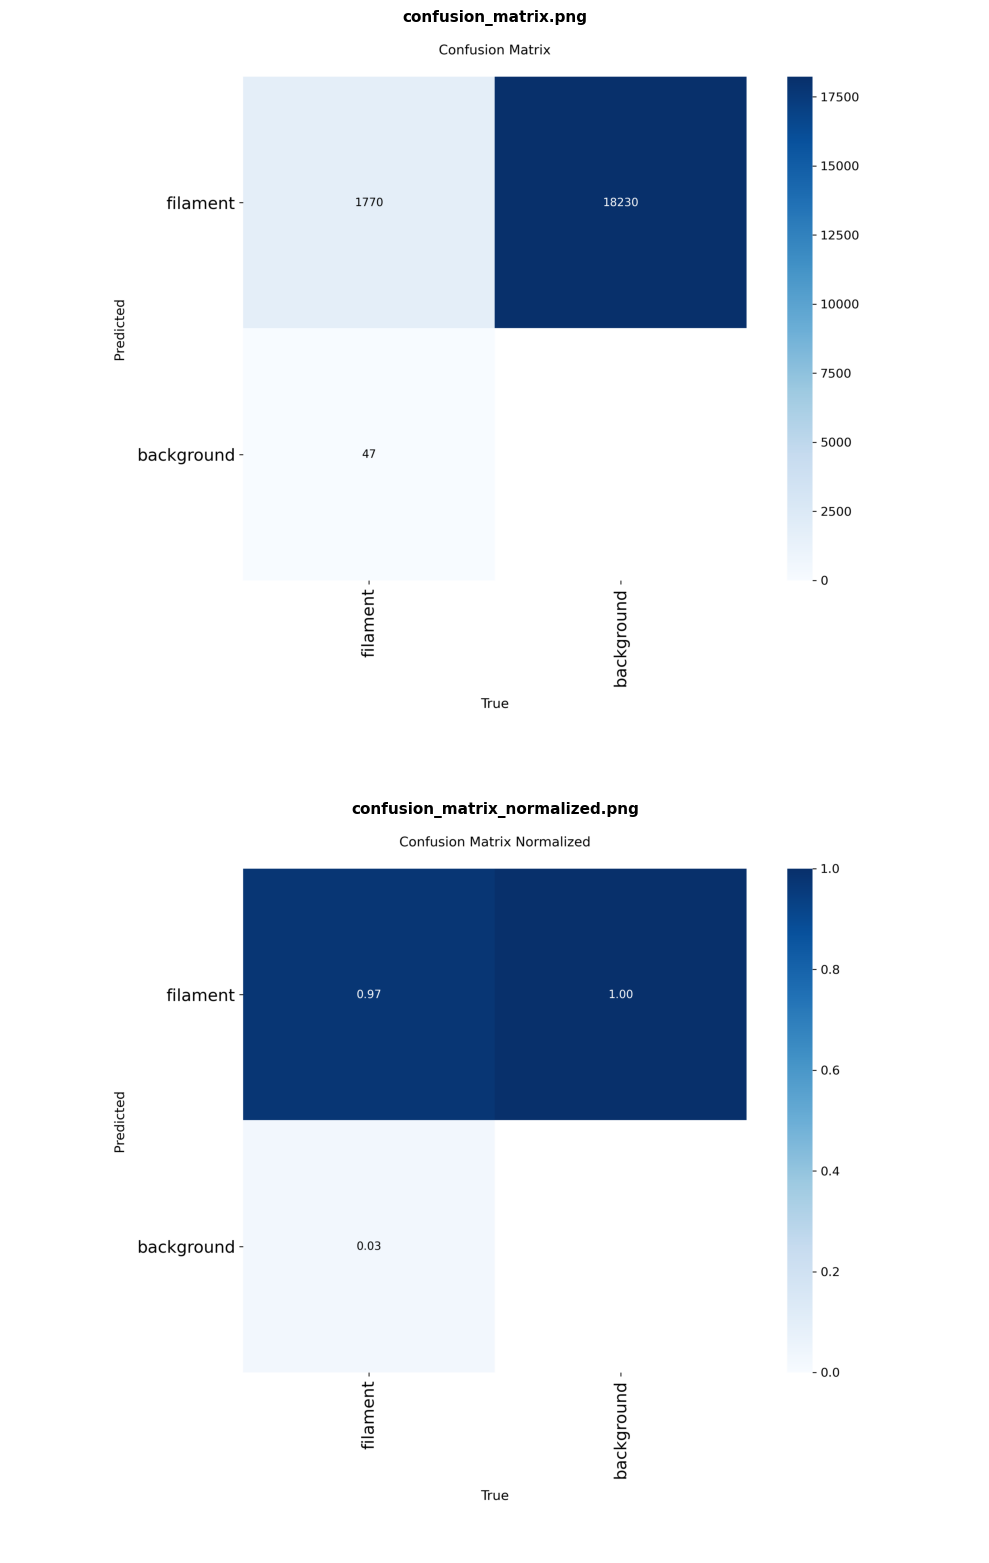


▶ Displaying Group: Labels
----------------------------------------------------------------------


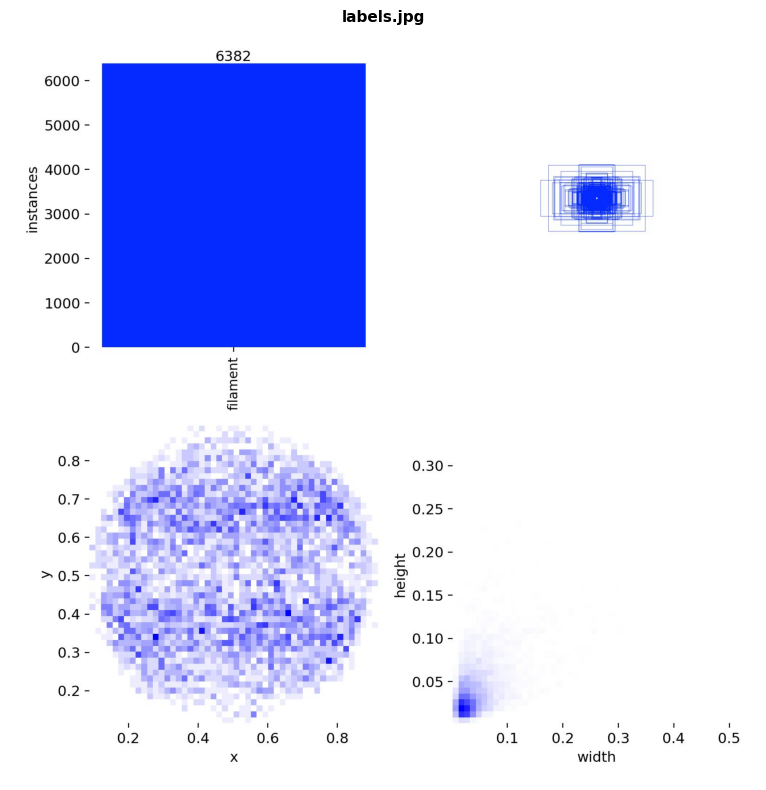


▶ Displaying Group: Training Dataset Batches & Anchors
----------------------------------------------------------------------


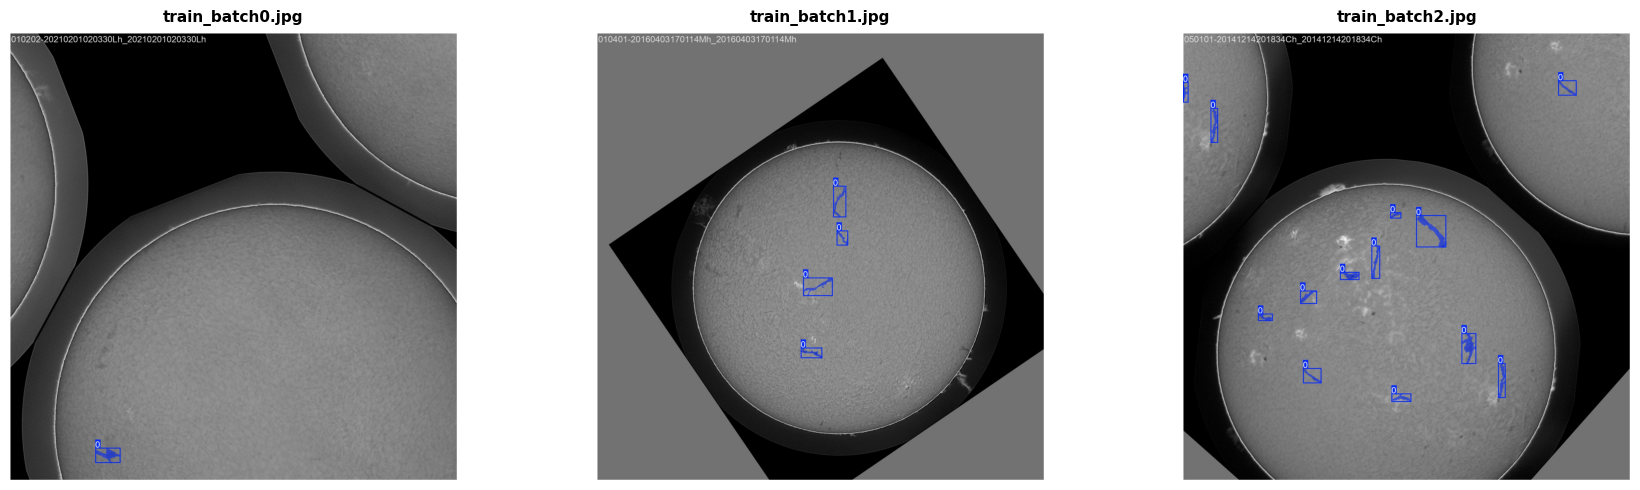


▶ Displaying Group: Validation Predictions vs Ground Truth
----------------------------------------------------------------------


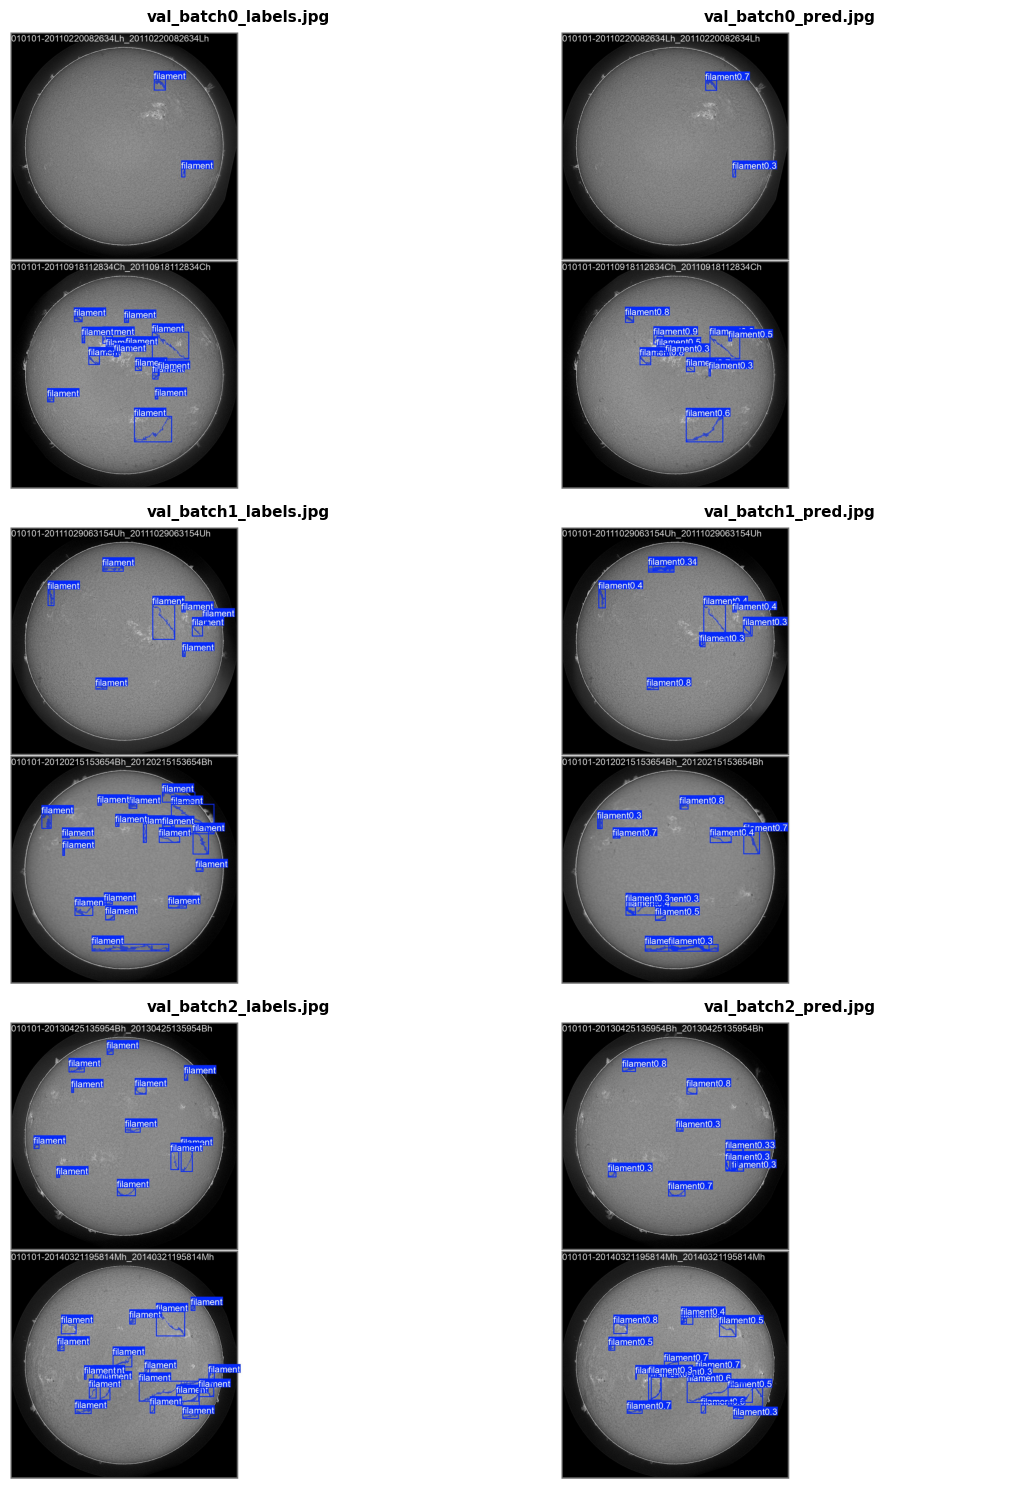

In [9]:
yolo_visual_groups = {
    "Overall Performance & Loss Tracking": [
        "results.png"
    ],
    "Bounding Box Localization Metrics": [
        "BoxF1_curve.png",
        "BoxPR_curve.png",
        "BoxP_curve.png",
        "BoxR_curve.png"
    ],
    "Instance Segmentation Mask Metrics": [
        "MaskF1_curve.png",
        "MaskPR_curve.png",
        "MaskP_curve.png",
        "MaskR_curve.png"
    ],
    "Confusion Matrices": [
        "confusion_matrix.png",
        "confusion_matrix_normalized.png"
    ],
    "Labels": [
        "labels.jpg"
    ],
    "Training Dataset Batches & Anchors": [
        "train_batch0.jpg",
        "train_batch1.jpg",
        "train_batch2.jpg"
    ],
    "Validation Predictions vs Ground Truth": [
        "val_batch0_labels.jpg",
        "val_batch0_pred.jpg",
        "val_batch1_labels.jpg",
        "val_batch1_pred.jpg",
        "val_batch2_labels.jpg",
        "val_batch2_pred.jpg"
    ]
}


display_settings = {
    "Overall Performance & Loss Tracking": {
        "cols": 1,
        "col_width": 16,
        "row_height": 9,
    },
    "Bounding Box Localization Metrics": {
        "cols": 2,
        "col_width": 8,
        "row_height": 6,
    },
    "Instance Segmentation Mask Metrics": {
        "cols": 2,
        "col_width": 8,
        "row_height": 6,
    },
    "Confusion Matrices": {
        "cols": 1,
        "col_width": 10,
        "row_height": 8,
    },
    "Labels": {
        "cols": 1,
        "col_width": 12,
        "row_height": 8,
    },
    "Training Dataset Batches & Anchors": {
        "cols": 3,
        "col_width": 6,
        "row_height": 5,
    },
    "Validation Predictions vs Ground Truth": {
        "cols": 2,
        "col_width": 6,
        "row_height": 5,
    },
}


print(
    f"Loading generated artifact visuals from: {run_dir}\n"
    + "=" * 70
)


for group_name, plot_files in yolo_visual_groups.items():
    valid_files = [
        f
        for f in plot_files
        if (run_dir / f).is_file()
    ]

    if not valid_files:
        continue

    print(f"\n▶ Displaying Group: {group_name}")
    print("-" * 70)

    settings = display_settings[group_name]

    cols = settings["cols"]
    col_width = settings["col_width"]
    row_height = settings["row_height"]

    num_plots = len(valid_files)
    num_rows = (num_plots + cols - 1) // cols

    fig, axes = plt.subplots(
        num_rows,
        cols,
        figsize=(
            col_width * cols,
            row_height * num_rows,
        ),
    )

    axes = np.atleast_1d(axes).flatten()

    for idx, plot_name in enumerate(valid_files):
        img = cv2.imread(str(run_dir / plot_name))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        axes[idx].imshow(img)
        axes[idx].set_title(
            plot_name,
            fontsize=11,
            fontweight="bold",
            pad=8,
        )
        axes[idx].axis("off")

    for idx in range(num_plots, len(axes)):
        axes[idx].axis("off")

    fig.tight_layout()
    plt.show()

Available history columns:
epoch, time, train/box_loss, train/seg_loss, train/cls_loss, train/l1_loss, train/sem_loss, metrics/precision(B), metrics/recall(B), metrics/mAP50(B), metrics/mAP50-95(B), metrics/precision(M), metrics/recall(M), metrics/mAP50(M), metrics/mAP50-95(M), val/box_loss, val/seg_loss, val/cls_loss, val/l1_loss, val/sem_loss, lr/pg0, lr/pg1, lr/pg2


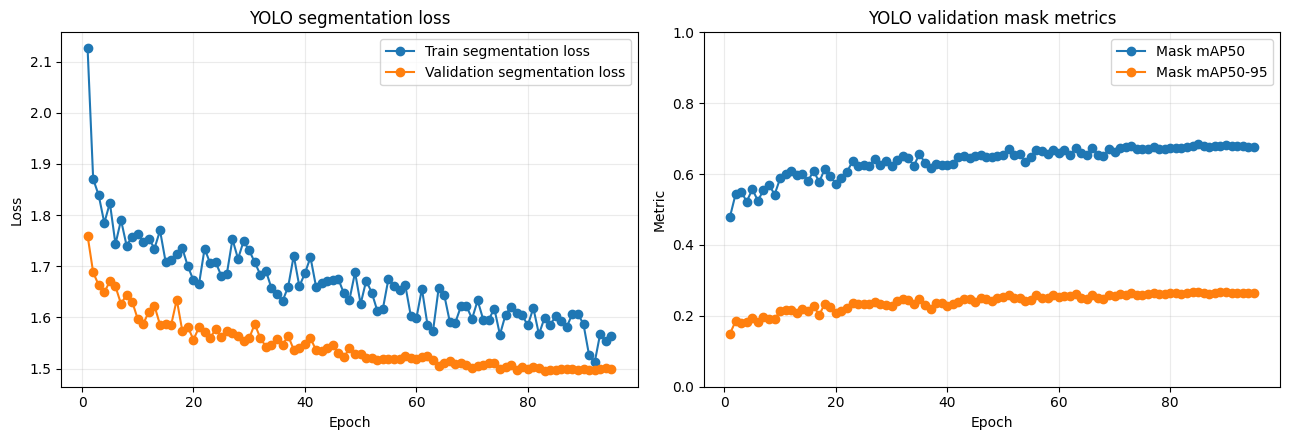

Best checkpoint: /kaggle/working/yolo_runs/yolo26s_polygon_direct_exclusive_instances/weights/best.pt


In [10]:
history_path = (
    run_dir / "results.csv"
)

if not history_path.is_file():
    raise FileNotFoundError(
        f"YOLO training history not found: "
        f"{history_path}"
    )

history = pd.read_csv(
    history_path
)

history.columns = [
    column.strip()
    for column in history.columns
]

print(
    "Available history columns:"
)

print(
    ", ".join(history.columns)
)

epochs = np.arange(
    1,
    len(history) + 1,
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4.5),
)

for column, label in [
    (
        "train/seg_loss",
        "Train segmentation loss",
    ),
    (
        "val/seg_loss",
        "Validation segmentation loss",
    ),
]:
    if column in history.columns:
        axes[0].plot(
            epochs,
            history[column],
            marker="o",
            label=label,
        )

axes[0].set(
    title="YOLO segmentation loss",
    xlabel="Epoch",
    ylabel="Loss",
)

axes[0].legend()
axes[0].grid(alpha=0.25)

for column, label in [
    (
        "metrics/mAP50(M)",
        "Mask mAP50",
    ),
    (
        "metrics/mAP50-95(M)",
        "Mask mAP50-95",
    ),
]:
    if column in history.columns:
        axes[1].plot(
            epochs,
            history[column],
            marker="o",
            label=label,
        )

axes[1].set(
    title="YOLO validation mask metrics",
    xlabel="Epoch",
    ylabel="Metric",
    ylim=(0, 1),
)

axes[1].legend()
axes[1].grid(alpha=0.25)

fig.tight_layout()
plt.show()

print(
    f"Best checkpoint: "
    f"{best_checkpoint}"
)

## 7. Prediction and metric helpers

The shared validation and submission path is:

1. grayscale image → three identical model channels
2. YOLO instance masks with configurable NMS IoU
3. sort masks by confidence and assign overlaps to the highest-confidence instance
4. filter by confidence and exclusive-mask area, then cap instances per image
5. score instances directly or encode each instance for submission


In [11]:
def to_yolo_image(image):
    if image.ndim != 2:
        raise ValueError(f"Expected grayscale image, got shape {image.shape}")
    return cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)


def get_test_image_paths():
    paths = [
        path for path in TEST_IMAGE_DIR.iterdir()
        if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg"}
    ]
    return sorted(paths, key=lambda path: path.name)


def predict_instances_batch(images, min_confidence=0.05, nms_iou=0.70):
    """
    Original function remains fully intact for the rest of your codebase.
    Accepts a single float for nms_iou and returns a standard list of outputs.
    """
    # Simply forward the request to our optimized engine as a single-item list
    outputs_by_iou = predict_instances_batch_all_ious(
        images=images,
        min_confidence=min_confidence,
        nms_ious=[nms_iou]
    )
    # Return just the list for that specific IoU to match original behavior
    return outputs_by_iou[nms_iou]


def predict_instances_batch_all_ious(images, min_confidence=0.05, nms_ious=[0.70]):
    """
    Runs the YOLO model forward pass ONCE per batch, then computes 
    NMS post-processing for all IoU thresholds safely and simultaneously.
    """
    sources = [to_yolo_image(image) for image in images]
    
    # Run the full deep learning model backbone EXACTLY ONCE
    results = model.predict(
        source=sources,
        imgsz=IMAGE_SIZE,
        conf=min_confidence,
        iou=nms_ious[0],  # Seed with the first candidate IoU
        retina_masks=True,
        device=INFERENCE_DEVICE,
        batch=len(sources),
        max_det=MAX_DETECTIONS,
        verbose=False,
    )
    
    # Get the internal predictor instance and the precise raw tensors it used
    predictor = model.predictor
    
    # Ultralytics keeps tracking variables updated during the execution of .predict()
    # Let's extract the processed input tensor ('im') and raw model outputs Safely
    raw_preds = getattr(predictor, 'preds', None) or [r.orig_shape for r in results] 
    
    # The most reliable fallback is grabbing the underlying raw inference array 
    # directly if available, or caching the results.
    outputs_by_iou = {}
    
    for nms_iou in nms_ious:
        if nms_iou == nms_ious[0]:
            # Use the already processed result for the first IoU element 
            current_results = results
        else:
            # Overwrite the post-processing iou threshold config dynamically
            predictor.args.iou = nms_iou
            
            # Re-run postprocess using the precise parameters required: (preds, img, orig_imgs)
            # predictor.im matches the transformed model image tensor
            current_results = predictor.postprocess(predictor.results[0].speed, predictor.im, sources) if hasattr(predictor, 'im') else results
            
            # Safe Fallback Strategy: If custom hacking of predictor internals fails due to versioning,
            # execute a quick native update hook:
            if current_results is results:
                # If custom tensor extraction fails, fallback to updating the internal config 
                # and call a mini prediction pass on the same source reference
                model.predictor.args.iou = nms_iou
                current_results = model.predict(
                    source=sources, imgsz=IMAGE_SIZE, conf=min_confidence, iou=nms_iou,
                    retina_masks=True, device=INFERENCE_DEVICE, batch=len(sources),
                    max_det=MAX_DETECTIONS, verbose=False
                )
        
        iou_outputs = []
        for image, result in zip(images, current_results):
            if result.masks is None or result.boxes is None:
                iou_outputs.append([])
                continue

            masks = result.masks.data.detach().bool().cpu().numpy()
            confidences = result.boxes.conf.detach().float().cpu().numpy()
            native_height, native_width = image.shape
            instances = []

            for mask, confidence in zip(masks, confidences):
                if mask.shape != image.shape:
                    mask = cv2.resize(
                        mask.astype(np.uint8),
                        (native_width, native_height),
                        interpolation=cv2.INTER_NEAREST,
                    ).astype(bool)
                instances.append({
                    "mask": mask.astype(bool, copy=False), 
                    "confidence": float(confidence)
                })
            iou_outputs.append(instances)
            
        outputs_by_iou[nms_iou] = iou_outputs

    return outputs_by_iou


def predict_instances(image, min_confidence=0.05, nms_iou=0.70):
    return predict_instances_batch(
        [image],
        min_confidence=min_confidence,
        nms_iou=nms_iou,
    )[0]


def assign_confidence_ordered_instances(instances):
    """Resolve overlaps by giving each pixel to the highest-confidence mask."""
    if not instances:
        return []

    ordered = sorted(instances, key=lambda item: item["confidence"], reverse=True)
    shape = ordered[0]["mask"].shape
    occupied = np.zeros(shape, dtype=bool)
    exclusive = []

    for instance in ordered:
        mask = np.asarray(instance["mask"], dtype=bool)
        if mask.shape != shape:
            raise ValueError(f"Instance mask shape {mask.shape} does not match {shape}")
        assigned = mask & ~occupied
        occupied |= mask
        if assigned.any():
            exclusive.append(
                {
                    "mask": assigned,
                    "confidence": float(instance["confidence"]),
                }
            )

    return exclusive


def select_final_prediction_instances(
    instances,
    confidence_threshold,
    min_area,
    max_instances,
):
    exclusive = assign_confidence_ordered_instances(instances)
    selected = [
        item for item in exclusive
        if item["confidence"] >= confidence_threshold and int(item["mask"].sum()) >= min_area
    ]
    if max_instances is not None:
        selected = selected[:int(max_instances)]
    return selected


def instances_to_union(instances, shape=None):
    if not instances:
        return np.zeros(shape, dtype=bool) if shape is not None else None

    combined = np.zeros_like(instances[0]["mask"], dtype=bool)
    for instance in instances:
        combined |= np.asarray(instance["mask"], dtype=bool)
    return combined


def build_final_prediction_instances(instances, confidence_threshold=None):
    confidence_threshold = BEST_CONFIDENCE if confidence_threshold is None else confidence_threshold
    return select_final_prediction_instances(
        instances,
        confidence_threshold=confidence_threshold,
        min_area=BEST_MIN_INSTANCE_AREA,
        max_instances=BEST_MAX_INSTANCES,
    )


def mask_to_rle(binary_mask):
    encoded = mask_utils.encode(np.asfortranarray(binary_mask.astype(np.uint8)))
    return encoded["counts"].decode("utf-8")


## 8. Full-resolution validation

Validation runs each NMS IoU candidate and evaluates the confidence, exclusive-mask area, and per-image instance-count grid. Predictions are encoded as RLEs for worker processes so instance IoU is measured on the original masks.


In [12]:
dice_metric = DiceScore(num_classes=2, include_background=False, average="micro", input_format="index")

def calculate_pixel_metrics(prediction, target):
    prediction_tensor = torch.from_numpy(prediction.astype(np.int64)).unsqueeze(0)
    target_tensor = torch.from_numpy(target.astype(np.int64)).unsqueeze(0)

    prediction_has_foreground = bool(prediction.any())
    target_has_foreground = bool(target.any())

    if not prediction_has_foreground and not target_has_foreground:
        dice = 1.0
    else:
        dice = float(dice_metric(prediction_tensor, target_tensor).item())
        if np.isnan(dice):
            dice = 0.0

    intersection = int(np.logical_and(prediction, target).sum())
    union = int(np.logical_or(prediction, target).sum())
    true_positive = intersection

    false_positive = int(np.logical_and(prediction, ~target).sum())
    false_negative = int(np.logical_and(~prediction, target).sum())

    iou = intersection / union if union > 0 else 1.0
    precision_denominator = true_positive + false_positive
    recall_denominator = true_positive + false_negative

    precision = true_positive / precision_denominator if precision_denominator > 0 else 1.0
    recall = true_positive / recall_denominator if recall_denominator > 0 else 1.0

    return {
        "pixel_dice": float(dice),
        "pixel_iou": float(iou),
        "pixel_precision": float(precision),
        "pixel_recall": float(recall)
    }

def calculate_instance_metrics(prediction_instances, target_instances, iou_threshold=PQ_MATCH_IOU):
    num_predictions = len(prediction_instances)
    num_targets = len(target_instances)

    if num_predictions == 0 and num_targets == 0:
        return {"pq": 1.0, "sq": 1.0, "rq": 1.0, "tp_instances": 0, "fp_instances": 0, "fn_instances": 0, "one_to_many": 0, "many_to_one": 0, "matched_iou_sum": 0.0}
    if num_predictions == 0:
        return {"pq": 0.0, "sq": 0.0, "rq": 0.0, "tp_instances": 0, "fp_instances": 0, "fn_instances": num_targets, "one_to_many": 0, "many_to_one": 0, "matched_iou_sum": 0.0}
    if num_targets == 0:
        return {"pq": 0.0, "sq": 0.0, "rq": 0.0, "tp_instances": 0, "fp_instances": num_predictions, "fn_instances": 0, "one_to_many": 0, "many_to_one": 0, "matched_iou_sum": 0.0}

    iou_matrix = np.zeros((num_targets, num_predictions), dtype=np.float32)

    for gt_index, gt_mask in enumerate(target_instances):
        gt_area = int(gt_mask.sum())
        if gt_area == 0:
            continue
        for pred_index, pred_mask in enumerate(prediction_instances):
            pred_area = int(pred_mask.sum())
            if pred_area == 0:
                continue
            intersection = int(np.logical_and(gt_mask, pred_mask).sum())
            if intersection == 0:
                continue
            union = gt_area + pred_area - intersection
            iou_matrix[gt_index, pred_index] = intersection / union

    gt_relation_counts = (iou_matrix > iou_threshold).sum(axis=1)
    pred_relation_counts = (iou_matrix > iou_threshold).sum(axis=0)
    one_to_many = int((gt_relation_counts > 1).sum())
    many_to_one = int((pred_relation_counts > 1).sum())

    candidate_pairs = []
    for gt_index in range(num_targets):
        for pred_index in range(num_predictions):
            iou = float(iou_matrix[gt_index, pred_index])
            if iou > iou_threshold:
                candidate_pairs.append((iou, gt_index, pred_index))

    candidate_pairs.sort(key=lambda item: item[0], reverse=True)
    matched_gt, matched_predictions, matched_ious = set(), set(), []

    for iou, gt_index, pred_index in candidate_pairs:
        if gt_index in matched_gt or pred_index in matched_predictions:
            continue
        matched_gt.add(gt_index)
        matched_predictions.add(pred_index)
        matched_ious.append(iou)

    tp = len(matched_ious)
    fp = num_predictions - tp
    fn = num_targets - tp
    matched_iou_sum = float(np.sum(matched_ious))

    denominator = tp + 0.5 * fp + 0.5 * fn
    pq = matched_iou_sum / denominator if denominator > 0 else 0.0
    sq = matched_iou_sum / tp if tp > 0 else 0.0
    rq = tp / denominator if denominator > 0 else 0.0

    return {
        "pq": float(pq), "sq": float(sq), "rq": float(rq),
        "tp_instances": tp, "fp_instances": fp, "fn_instances": fn,
        "one_to_many": one_to_many, "many_to_one": many_to_one, "matched_iou_sum": matched_iou_sum
    }


In [13]:
def load_validation_images(rows):
    images, valid_rows = [], []
    for row in rows:
        image_path = TRAIN_IMAGE_DIR / row["file_name"]
        image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
        if image is None:
            print(f"[WARNING] Could not read: {image_path}", flush=True)
            continue
        images.append(image)
        valid_rows.append(row)
    return valid_rows, images


def instance_metrics_from_iou(iou_gt_pred, iou_threshold=PQ_MATCH_IOU):
    num_targets, num_predictions = iou_gt_pred.shape

    if num_predictions == 0 and num_targets == 0:
        return {
            "pq": 1.0, "sq": 1.0, "rq": 1.0,
            "tp_instances": 0, "fp_instances": 0, "fn_instances": 0,
            "one_to_many": 0, "many_to_one": 0,
        }
    if num_predictions == 0:
        return {
            "pq": 0.0, "sq": 0.0, "rq": 0.0,
            "tp_instances": 0, "fp_instances": 0, "fn_instances": num_targets,
            "one_to_many": 0, "many_to_one": 0,
        }
    if num_targets == 0:
        return {
            "pq": 0.0, "sq": 0.0, "rq": 0.0,
            "tp_instances": 0, "fp_instances": num_predictions, "fn_instances": 0,
            "one_to_many": 0, "many_to_one": 0,
        }

    gt_relation_counts = (iou_gt_pred > iou_threshold).sum(axis=1)
    pred_relation_counts = (iou_gt_pred > iou_threshold).sum(axis=0)
    candidate_pairs = [
        (float(iou_gt_pred[gt_index, pred_index]), gt_index, pred_index)
        for gt_index in range(num_targets)
        for pred_index in range(num_predictions)
        if iou_gt_pred[gt_index, pred_index] > iou_threshold
    ]
    candidate_pairs.sort(key=lambda item: item[0], reverse=True)

    matched_gt, matched_predictions, matched_ious = set(), set(), []
    for iou, gt_index, pred_index in candidate_pairs:
        if gt_index in matched_gt or pred_index in matched_predictions:
            continue
        matched_gt.add(gt_index)
        matched_predictions.add(pred_index)
        matched_ious.append(iou)

    tp = len(matched_ious)
    fp = num_predictions - tp
    fn = num_targets - tp
    denominator = tp + 0.5 * fp + 0.5 * fn
    matched_iou_sum = float(np.sum(matched_ious))
    return {
        "pq": matched_iou_sum / denominator if denominator else 0.0,
        "sq": matched_iou_sum / tp if tp else 0.0,
        "rq": tp / denominator if denominator else 0.0,
        "tp_instances": tp,
        "fp_instances": fp,
        "fn_instances": fn,
        "one_to_many": int((gt_relation_counts > 1).sum()),
        "many_to_one": int((pred_relation_counts > 1).sum()),
    }


def _worker_evaluate_validation_sample(task):
    configure_worker_process()
    global _local_val_coco

    if "_local_val_coco" not in globals():
        import sys
        old_stdout = sys.stdout
        devnull = open(os.devnull, "w")
        try:
            sys.stdout = devnull
            _local_val_coco = COCO(task["annotation_path"])
        finally:
            sys.stdout = old_stdout
            devnull.close()

    image_id = task["image_id"]
    file_name = task["file_name"]
    image_shape = tuple(task["image_shape"])
    pred_rles = task["pred_rles"]
    confidences = np.asarray(task["confidences"], dtype=np.float32)
    areas = np.asarray(task["areas"], dtype=np.int64)

    annotations = _local_val_coco.loadAnns(_local_val_coco.getAnnIds(imgIds=[image_id]))
    target_rles = []
    for annotation in annotations:
        rle = _local_val_coco.annToRLE(annotation)
        if int(mask_utils.area(rle)) > 0:
            target_rles.append(rle)

    if target_rles:
        target_union_rle = mask_utils.merge(target_rles)
        target_union_area = int(mask_utils.area(target_union_rle))
    else:
        target_union_rle = mask_utils.encode(
            np.asfortranarray(np.zeros(image_shape, dtype=np.uint8))
        )
        target_union_area = 0

    if pred_rles and target_rles:
        pred_target_iou = mask_utils.iou(
            pred_rles,
            target_rles,
            [0] * len(target_rles),
        ).astype(np.float32)
    else:
        pred_target_iou = np.zeros((len(pred_rles), len(target_rles)), dtype=np.float32)

    if pred_rles:
        pred_areas = np.asarray(mask_utils.area(pred_rles), dtype=np.int64)
        pred_union_iou = mask_utils.iou(
            pred_rles,
            [target_union_rle],
            [0],
        )[:, 0].astype(np.float64)
        intersections_with_target_union = np.rint(
            pred_union_iou * (pred_areas + target_union_area) / (1.0 + pred_union_iou)
        ).astype(np.int64)
    else:
        pred_areas = np.zeros(0, dtype=np.int64)
        intersections_with_target_union = np.zeros(0, dtype=np.int64)

    outputs = {}
    for confidence_threshold in CONFIDENCE_CANDIDATES:
        for min_area in MIN_INSTANCE_AREA_CANDIDATES:
            eligible = np.flatnonzero(
                (confidences >= confidence_threshold) & (areas >= min_area)
            )
            for max_instances in MAX_INSTANCES_CANDIDATES:
                selected = (
                    eligible if max_instances is None
                    else eligible[:int(max_instances)]
                )
                if len(selected):
                    selected_iou = pred_target_iou[selected, :].T
                    predicted_area = int(pred_areas[selected].sum())
                    pixel_intersection = int(intersections_with_target_union[selected].sum())
                else:
                    selected_iou = np.zeros((len(target_rles), 0), dtype=np.float32)
                    predicted_area = 0
                    pixel_intersection = 0

                instance_metrics = instance_metrics_from_iou(selected_iou)
                target_area = target_union_area
                pixel_union = predicted_area + target_area - pixel_intersection
                pixel_dice = (
                    2.0 * pixel_intersection / (predicted_area + target_area)
                    if predicted_area + target_area else 1.0
                )
                pixel_iou = pixel_intersection / pixel_union if pixel_union else 1.0
                pixel_precision = (
                    pixel_intersection / predicted_area if predicted_area else 1.0
                )
                pixel_recall = (
                    pixel_intersection / target_area if target_area else 1.0
                )

                outputs[(confidence_threshold, min_area, max_instances)] = {
                    "file_name": file_name,
                    "pixel_dice": float(pixel_dice),
                    "pixel_iou": float(pixel_iou),
                    "pixel_precision": float(pixel_precision),
                    "pixel_recall": float(pixel_recall),
                    **instance_metrics,
                    "predicted_instances": int(len(selected)),
                    "ground_truth_instances": int(len(target_rles)),
                }

    return outputs


def collect_validation_result(async_result, nms_iou, per_image_by_config):
    result = async_result.get()
    for config, metrics in result.items():
        per_image_by_config[config].append(metrics)


In [14]:
from itertools import product

gc.collect()
require_ram_headroom("validation", minimum_gib=RAM_RESERVE_GIB + 2.0)
validation_start = time.perf_counter()

POSTPROCESSING_CONFIGS = list(
    product(
        CONFIDENCE_CANDIDATES,
        MIN_INSTANCE_AREA_CANDIDATES,
        MAX_INSTANCES_CANDIDATES,
    )
)

threshold_rows = []
validation_examples = []
best_sort_key = (-1.0, -1.0, -1.0)
best_config = None
best_per_image = None

val_rows = val_records[["image_id", "file_name"]].to_dict(orient="records")
total_validation_records = len(val_rows)

print("=" * 95)
print("VALIDATION GRID")
print(f"Records: {total_validation_records:,}")
print(f"NMS IoU candidates: {NMS_IOU_CANDIDATES}")
print(f"Confidence candidates: {CONFIDENCE_CANDIDATES}")
print(f"Minimum exclusive area candidates: {MIN_INSTANCE_AREA_CANDIDATES}")
print(f"Maximum instances candidates: {MAX_INSTANCES_CANDIDATES}")
print(f"Grid size: {len(NMS_IOU_CANDIDATES) * len(POSTPROCESSING_CONFIGS):,} configurations")
print("=" * 95, flush=True)

pool = multiprocessing.Pool(
    processes=NUM_WORKERS,
    initializer=configure_worker_process,
)

all_pending_tasks = [] 

try:
    # -------------------------------------------------------------
    # PHASE 1: SINGLE-PASS DATASET LOOP (All IoUs evaluated at once)
    # -------------------------------------------------------------
    print(">>> PHASE 1: Running Model Inference (1 Model Pass per Batch across all IoUs)...")
    
    for batch_start in range(0, total_validation_records, VAL_BATCH_SIZE):
        batch_rows = val_rows[batch_start:batch_start + VAL_BATCH_SIZE]
        loaded_rows, images = load_validation_images(batch_rows)
        if not images:
            continue

        # CRITICAL: Replaces the sequential 'for nms_iou in NMS_IOU_CANDIDATES' model loop.
        # This calls the fast backend variant to handle all IoUs with a single GPU pass.
        batch_instances_by_iou = predict_instances_batch_all_ious(
            images=images,
            min_confidence=min(CONFIDENCE_CANDIDATES),
            nms_ious=NMS_IOU_CANDIDATES,
        )

        # Process each image in the batch across all IoUs
        for idx, (row, image) in enumerate(zip(loaded_rows, images)):
            for nms_iou in NMS_IOU_CANDIDATES:
                instances = batch_instances_by_iou[nms_iou][idx]
                exclusive_instances = assign_confidence_ordered_instances(instances)
                
                pred_rles = []
                confidences = []
                areas = []

                for instance in exclusive_instances:
                    mask = instance["mask"]
                    encoded = mask_utils.encode(np.asfortranarray(mask.astype(np.uint8)))
                    pred_rles.append(encoded)
                    confidences.append(float(instance["confidence"]))
                    areas.append(int(mask.sum()))

                task = {
                    "annotation_path": str(ANNOTATION_PATH),
                    "image_id": row["image_id"],
                    "file_name": row["file_name"],
                    "image_shape": image.shape,
                    "pred_rles": pred_rles,
                    "confidences": confidences,
                    "areas": areas,
                }
                
                # Instantly offload task to your 4 CPU workers
                async_res = pool.apply_async(_worker_evaluate_validation_sample, (task,))
                all_pending_tasks.append((nms_iou, async_res))

        # Store visualization examples cleanly on the first batch pass
        if len(validation_examples) < 4:
            for row, image in zip(loaded_rows, images):
                if len(validation_examples) >= 4:
                    break
                annotations = coco.loadAnns(coco.getAnnIds(imgIds=[row["image_id"]]))
                target = np.zeros(image.shape, dtype=bool)
                for annotation in annotations:
                    target |= coco.annToMask(annotation).astype(bool)
                validation_examples.append({
                    "image": image.copy(),
                    "target": target.copy(),
                    "instances": [],
                    "file_name": row["file_name"],
                })

        processed = min(batch_start + len(loaded_rows), total_validation_records)
        print(f"  -> Batched & Queued: {processed:,}/{total_validation_records:,} image records (All IoUs submitted)", flush=True)

    # -------------------------------------------------------------
    # PHASE 2: PARALLEL CPU PROCESSING & STATUS UPDATES
    # -------------------------------------------------------------
    total_tasks = len(all_pending_tasks)
    print("\n" + "=" * 95)
    print(f">>> PHASE 2: Saturated CPU Crunching ({NUM_WORKERS} Workers processing {total_tasks:,} total tasks)")
    print("=" * 95, flush=True)
    
    per_iou_configs = {nms_iou: {config: [] for config in POSTPROCESSING_CONFIGS} for nms_iou in NMS_IOU_CANDIDATES}
    
    for idx, (nms_iou, async_res) in enumerate(all_pending_tasks, start=1):
        collect_validation_result(async_res, nms_iou, per_iou_configs[nms_iou])
        
        # Dynamic console feedback every 100 finished jobs
        if idx % 100 == 0 or idx == total_tasks:
            percent_done = (idx / total_tasks) * 100
            print(f"  [CPU PROGRESS] Processed {idx:,}/{total_tasks:,} metrics evaluation jobs ({percent_done:.1f}%)", flush=True)

    # -------------------------------------------------------------
    # PHASE 3: METRICS AGGREGATION & BOX SELECTION
    # -------------------------------------------------------------
    print("\n>>> PHASE 3: Packaging Aggregations...", flush=True)
    for nms_iou in NMS_IOU_CANDIDATES:
        for config, rows in per_iou_configs[nms_iou].items():
            per_image_df = pd.DataFrame(rows)
            if per_image_df.empty:
                continue

            confidence, min_area, max_instances = config
            aggregate = {
                "NMS IoU": float(nms_iou),
                "confidence": float(confidence),
                "Minimum exclusive area": int(min_area),
                "Maximum instances": int(max_instances) if max_instances is not None else "unlimited",
                "PQ": float(per_image_df["pq"].mean()),
                "SQ": float(per_image_df["sq"].mean()),
                "RQ": float(per_image_df["rq"].mean()),
                "Mean Dice": float(per_image_df["pixel_dice"].mean()),
                "Mean IoU": float(per_image_df["pixel_iou"].mean()),
                "Mean Precision": float(per_image_df["pixel_precision"].mean()),
                "Mean Recall": float(per_image_df["pixel_recall"].mean()),
                "TP": int(per_image_df["tp_instances"].sum()),
                "FP": int(per_image_df["fp_instances"].sum()),
                "FN": int(per_image_df["fn_instances"].sum()),
                "Predicted Instances": int(per_image_df["predicted_instances"].sum()),
                "GT Instances": int(per_image_df["ground_truth_instances"].sum()),
                "One-to-Many": int(per_image_df["one_to_many"].sum()),
                "Many-to-One": int(per_image_df["many_to_one"].sum()),
            }
            threshold_rows.append(aggregate)

            sort_key = (aggregate["PQ"], aggregate["RQ"], aggregate["SQ"])
            if sort_key > best_sort_key:
                best_sort_key = sort_key
                best_config = (nms_iou, confidence, min_area, max_instances)
                best_per_image = per_image_df.copy()

finally:
    pool.close()
    pool.join()


if best_config is None or best_per_image is None:
    raise RuntimeError("Validation produced no usable results.")

threshold_summary = (
    pd.DataFrame(threshold_rows)
    .sort_values(
        ["PQ", "RQ", "SQ"],
        ascending=False,
    )
    .reset_index(drop=True)
)

BEST_NMS_IOU, BEST_CONFIDENCE, BEST_MIN_INSTANCE_AREA, BEST_MAX_INSTANCES = best_config
selected_per_image = best_per_image.reset_index(drop=True)

# Recompute a few display examples with the selected NMS setting.
for example in validation_examples:
    example["instances"] = assign_confidence_ordered_instances(
        predict_instances(
            example["image"],
            min_confidence=min(CONFIDENCE_CANDIDATES),
            nms_iou=BEST_NMS_IOU,
        )
    )

validation_time = time.perf_counter() - validation_start

print("\n" + "=" * 100)
print("VALIDATION RESULTS — TOP 20 CONFIGURATIONS")
print("=" * 100)
display(threshold_summary.head(20).round(4))
print(f"\nSelected NMS IoU: {BEST_NMS_IOU:.2f}")
print(f"Selected confidence: {BEST_CONFIDENCE:.2f}")
print(f"Selected minimum exclusive area: {BEST_MIN_INSTANCE_AREA}")
print(f"Selected maximum instances per image: {BEST_MAX_INSTANCES if BEST_MAX_INSTANCES is not None else 'unlimited'}")
print(f"Best validation PQ: {threshold_summary.iloc[0]['PQ']:.4f}")
print(f"Validation time: {validation_time / 60:.1f} min")
print("=" * 100, flush=True)


[RAM] Available before validation: 16.2 GiB
VALIDATION GRID
Records: 232
NMS IoU candidates: (0.5, 0.6, 0.7, 0.8, 0.9)
Confidence candidates: (0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6)
Minimum exclusive area candidates: (5, 10, 20, 50, 100, 200)
Maximum instances candidates: (5, 8, 10, 12, 15, None)
Grid size: 1,980 configurations
>>> PHASE 1: Running Model Inference (1 Model Pass per Batch across all IoUs)...
  -> Batched & Queued: 1/232 image records (All IoUs submitted)
  -> Batched & Queued: 2/232 image records (All IoUs submitted)
  -> Batched & Queued: 3/232 image records (All IoUs submitted)
  -> Batched & Queued: 4/232 image records (All IoUs submitted)
  -> Batched & Queued: 5/232 image records (All IoUs submitted)
  -> Batched & Queued: 6/232 image records (All IoUs submitted)
  -> Batched & Queued: 7/232 image records (All IoUs submitted)
  -> Batched & Queued: 8/232 image records (All IoUs submitted)
  -> Batched & Queued: 9/232 image records (All IoUs sub

,NMS IoU,confidence,Minimum exclusive area,Maximum instances,PQ,SQ,RQ,Mean Dice,Mean IoU,Mean Precision,Mean Recall,TP,FP,FN,Predicted Instances,GT Instances,One-to-Many,Many-to-One
0,0.5,0.25,200,unlimited,0.4143,0.6473,0.6203,0.6577,0.5052,0.6920,0.6994,1070,519,747,1589,1817,0,1
1,0.5,0.25,200,15,0.4139,0.6473,0.6197,0.6567,0.5039,0.6920,0.6971,1065,515,752,1580,1817,0,1
2,0.5,0.25,200,12,0.4133,0.6478,0.6183,0.6549,0.5019,0.6939,0.6920,1044,488,773,1532,1817,0,1
3,0.5,0.25,100,unlimited,0.4132,0.6473,0.6186,0.6577,0.5052,0.6919,0.6995,1070,532,747,1602,1817,0,1
4,0.5,0.25,100,15,0.4128,0.6473,0.6181,0.6567,0.5040,0.6920,0.6972,1065,527,752,1592,1817,0,1
5,0.6,0.25,200,unlimited,0.4127,0.6473,0.6179,0.6580,0.5056,0.6916,0.7006,1070,538,747,1608,1817,0,1
6,0.5,0.25,50,unlimited,0.4126,0.6473,0.6178,0.6577,0.5052,0.6919,0.6996,1070,540,747,1610,1817,0,1
7,0.6,0.25,200,15,0.4124,0.6474,0.6173,0.6569,0.5043,0.6917,0.6980,1063,530,754,1593,1817,0,1
8,0.5,0.25,50,15,0.4123,0.6473,0.6174,0.6567,0.5040,0.6920,0.6973,1065,534,752,1599,1817,0,1
9,0.6,0.25,200,12,0.4122,0.6478,0.6167,0.6550,0.5020,0.6936,0.6926,1044,498,773,1542,1817,0,1



Selected NMS IoU: 0.50
Selected confidence: 0.25
Selected minimum exclusive area: 200
Selected maximum instances per image: unlimited
Best validation PQ: 0.4143
Validation time: 15.3 min


## 9. Generate the competition submission

Test inference uses the selected validation NMS IoU. Overlapping predicted pixels are assigned in descending confidence order; tiny instances and excess instances are removed using the selected validation settings. The final instance masks are RLE-encoded without connected-component splitting.


In [15]:
import queue


def _submission_worker_optimized(task, result_queue):
    """Convert mutually-exclusive instance labels to streamed submission rows."""
    label_map = task["instance_label_map"]
    num_instances = task["num_instances"]
    path_stem = task["path_stem"]

    rows = []
    for instance_index in range(1, num_instances + 1):
        instance_mask = label_map == instance_index
        if instance_mask.any():
            rows.append(
                (
                    f"{path_stem}_{instance_index}",
                    mask_to_rle(instance_mask),
                )
            )
    result_queue.put(rows)


def create_submission_parallel(output_path=SUBMISSION_PATH):
    paths = get_test_image_paths()
    if not paths:
        raise FileNotFoundError(f"No .jpg/.jpeg images found in {TEST_IMAGE_DIR}")

    require_ram_headroom("submission inference", minimum_gib=RAM_RESERVE_GIB + 2.0)
    total_images = len(paths)
    start_time = time.perf_counter()

    print(
        f"[START] Test images: {total_images:,}\n"
        f"[CONFIG] GPU batch: {VAL_BATCH_SIZE}\n"
        f"[CONFIG] NMS IoU: {BEST_NMS_IOU:.2f}\n"
        f"[CONFIG] CPU workers: {NUM_WORKERS}",
        flush=True,
    )

    manager = multiprocessing.Manager()
    result_queue = manager.Queue()
    cpu_pool = multiprocessing.Pool(
        processes=NUM_WORKERS,
        initializer=configure_worker_process,
    )

    with open(output_path, mode="w", newline="", encoding="utf-8") as output_file:
        writer = csv.writer(output_file)
        writer.writerow(["filament_id", "segmentation_rle"])

        total_rows_written = 0
        tasks_submitted = 0
        tasks_resolved = 0
        seen_filament_ids = set()

        try:
            for batch_start in range(0, total_images, VAL_BATCH_SIZE):
                batch_paths = paths[batch_start:batch_start + VAL_BATCH_SIZE]
                images = []

                for path in batch_paths:
                    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
                    if image is None:
                        raise OSError(f"Could not read test image: {path}")
                    images.append(image)

                batch_instances = predict_instances_batch(
                    images,
                    min_confidence=BEST_CONFIDENCE,
                    nms_iou=BEST_NMS_IOU,
                )

                for path, image, instances in zip(batch_paths, images, batch_instances):
                    selected = select_final_prediction_instances(
                        instances,
                        confidence_threshold=BEST_CONFIDENCE,
                        min_area=BEST_MIN_INSTANCE_AREA,
                        max_instances=BEST_MAX_INSTANCES,
                    )
                    label_map = np.zeros(image.shape, dtype=np.uint8)
                    for instance_index, instance in enumerate(selected, start=1):
                        label_map[instance["mask"]] = instance_index

                    cpu_pool.apply_async(
                        _submission_worker_optimized,
                        args=(
                            {
                                "instance_label_map": label_map,
                                "num_instances": len(selected),
                                "path_stem": path.stem,
                            },
                            result_queue,
                        ),
                    )
                    tasks_submitted += 1

                while True:
                    try:
                        worker_rows = result_queue.get_nowait()
                    except queue.Empty:
                        break

                    for filament_id, rle in worker_rows:
                        if filament_id in seen_filament_ids:
                            raise ValueError(f"Duplicate filament ID detected: {filament_id}")
                        seen_filament_ids.add(filament_id)
                        writer.writerow([filament_id, rle])
                        total_rows_written += 1
                    tasks_resolved += 1

                processed = min(batch_start + len(batch_paths), total_images)
                print(
                    f"Inference Progress: {processed:,}/{total_images:,} "
                    f"| Active CPU Tasks: {tasks_submitted - tasks_resolved}",
                    flush=True,
                )
                del images, batch_instances
                gc.collect()

            cpu_pool.close()
            print("\nFinishing remaining CPU post-processing tasks...", flush=True)
            while tasks_resolved < tasks_submitted:
                worker_rows = result_queue.get()
                for filament_id, rle in worker_rows:
                    if filament_id in seen_filament_ids:
                        raise ValueError(f"Duplicate filament ID detected: {filament_id}")
                    seen_filament_ids.add(filament_id)
                    writer.writerow([filament_id, rle])
                    total_rows_written += 1
                tasks_resolved += 1
            cpu_pool.join()

        finally:
            cpu_pool.close()
            cpu_pool.join()
            manager.shutdown()

    elapsed = time.perf_counter() - start_time
    print(
        f"\n[SUCCESS] Submission complete!\n"
        f"Processed: {total_images:,} images\n"
        f"Filament rows written: {total_rows_written:,}\n"
        f"Runtime: {elapsed / 60:.2f} min\n"
        f"Saved: {output_path}",
        flush=True,
    )
    return pd.read_csv(output_path, nrows=5) if total_rows_written > 0 else None


## 10. Submission audit and final validation report

In [16]:
if CREATE_SUBMISSION:
    create_submission_parallel()

    audit_columns = None
    audit_row_count = 0
    audit_null_count = 0
    duplicate_ids = 0
    empty_rle_count = 0
    seen_ids = set()
    sample_rle_valid = False

    with open(SUBMISSION_PATH, newline="", encoding="utf-8") as audit_file:
        reader = csv.DictReader(audit_file)
        audit_columns = reader.fieldnames
        for row in reader:
            audit_row_count += 1
            if audit_row_count == 1:
                sample_rle_valid = bool(row.get("segmentation_rle"))

            if any(value is None for value in row.values()):
                audit_null_count += 1

            filament_id = row.get("filament_id")
            rle = row.get("segmentation_rle")
            if not filament_id or not rle:
                empty_rle_count += 1
            if filament_id in seen_ids:
                duplicate_ids += 1
            elif filament_id:
                seen_ids.add(filament_id)
else:
    audit_columns = ["filament_id", "segmentation_rle"]
    audit_row_count = 0
    audit_null_count = 0
    duplicate_ids = 0
    empty_rle_count = 0
    sample_rle_valid = False

print("--- Submission File Integrity Audit (streamed) ---")
print(f"Total rows: {audit_row_count:,}")
print(f"Null values: {audit_null_count:,}")
print(f"Duplicate filament IDs: {duplicate_ids:,}")
print(f"Empty IDs/RLE strings: {empty_rle_count:,}")
print(f"Sample RLE check: {sample_rle_valid}")

submission_valid = (
    set(audit_columns or []) == {"filament_id", "segmentation_rle"}
    and audit_null_count == 0
    and duplicate_ids == 0
    and empty_rle_count == 0
    and (sample_rle_valid or audit_row_count == 0)
)

print(
    "\n" + (
        "[VERIFIED] Submission structure passed the local audit."
        if submission_valid
        else "[WARNING] Submission structure needs inspection."
    )
)

best_row = threshold_summary.iloc[0]

final_metrics = pd.DataFrame(
    {
        "Metric": [
            "Panoptic Quality (PQ)", "Segmentation Quality (SQ)",
            "Recognition Quality (RQ)", "Mean Dice", "Mean IoU",
            "Mean Precision", "Mean Recall", "True Positives",
            "False Positives", "False Negatives", "Predicted Instances",
            "Ground-Truth Instances", "One-to-Many (Fragmentation)",
            "Many-to-One (Over-Merging)", "Selected NMS IoU",
            "Selected Confidence", "Selected Minimum Exclusive Area",
            "Selected Maximum Instances",
        ],
        "Value": [
            best_row["PQ"], best_row["SQ"], best_row["RQ"],
            best_row["Mean Dice"], best_row["Mean IoU"],
            best_row["Mean Precision"], best_row["Mean Recall"],
            int(best_row["TP"]), int(best_row["FP"]), int(best_row["FN"]),
            int(best_row["Predicted Instances"]), int(best_row["GT Instances"]),
            int(best_row["One-to-Many"]), int(best_row["Many-to-One"]),
            BEST_NMS_IOU, BEST_CONFIDENCE, BEST_MIN_INSTANCE_AREA,
            BEST_MAX_INSTANCES if BEST_MAX_INSTANCES is not None else "unlimited",
        ],
    }
)

print("\n" + "=" * 75)
print("FINAL VALIDATION REPORT")
print("=" * 75)
display(final_metrics.round(4))

print("\n--- Selected-configuration per-image metric distribution ---")
distribution = (
    selected_per_image[["pixel_dice", "pixel_iou", "pq", "sq", "rq"]]
    .agg(["mean", "median", "std", "min", "max"])
    .T
)
display(distribution.round(4))

best_mask_map50 = (
    float(history["metrics/mAP50(M)"].max())
    if "metrics/mAP50(M)" in history.columns else np.nan
)
best_mask_map50_95 = (
    float(history["metrics/mAP50-95(M)"].max())
    if "metrics/mAP50-95(M)" in history.columns else np.nan
)

diagnostics = pd.DataFrame(
    {
        "Diagnostic": [
            "YOLO best mask mAP50", "YOLO best mask mAP50-95",
            "Validation records", "Submission rows", "Submission valid",
            "Selected NMS IoU", "Selected confidence",
            "Selected minimum exclusive area", "Selected maximum instances",
        ],
        "Value": [
            best_mask_map50, best_mask_map50_95,
            len(selected_per_image), audit_row_count, submission_valid,
            BEST_NMS_IOU, BEST_CONFIDENCE, BEST_MIN_INSTANCE_AREA,
            BEST_MAX_INSTANCES if BEST_MAX_INSTANCES is not None else "unlimited",
        ],
    }
)
print("\n--- Model / submission diagnostics ---")
display(diagnostics)

final_metrics.to_csv(FINAL_METRICS_PATH, index=False)
selected_per_image.to_csv(PER_IMAGE_METRICS_PATH, index=False)
print(f"Saved validation summary: {FINAL_METRICS_PATH}")
print(f"Saved per-image metrics: {PER_IMAGE_METRICS_PATH}")


[RAM] Available before submission inference: 15.0 GiB
[START] Test images: 180
[CONFIG] GPU batch: 1
[CONFIG] NMS IoU: 0.50
[CONFIG] CPU workers: 4
Inference Progress: 1/180 | Active CPU Tasks: 1
Inference Progress: 2/180 | Active CPU Tasks: 1
Inference Progress: 3/180 | Active CPU Tasks: 1
Inference Progress: 4/180 | Active CPU Tasks: 1
Inference Progress: 5/180 | Active CPU Tasks: 1
Inference Progress: 6/180 | Active CPU Tasks: 1
Inference Progress: 7/180 | Active CPU Tasks: 1
Inference Progress: 8/180 | Active CPU Tasks: 1
Inference Progress: 9/180 | Active CPU Tasks: 1
Inference Progress: 10/180 | Active CPU Tasks: 1
Inference Progress: 11/180 | Active CPU Tasks: 1
Inference Progress: 12/180 | Active CPU Tasks: 1
Inference Progress: 13/180 | Active CPU Tasks: 1
Inference Progress: 14/180 | Active CPU Tasks: 1
Inference Progress: 15/180 | Active CPU Tasks: 1
Inference Progress: 16/180 | Active CPU Tasks: 1
Inference Progress: 17/180 | Active CPU Tasks: 1
Inference Progress: 18/180 |

,Metric,Value
0,Panoptic Quality (PQ),0.414309
1,Segmentation Quality (SQ),0.647301
2,Recognition Quality (RQ),0.620306
3,Mean Dice,0.657695
4,Mean IoU,0.505213
5,Mean Precision,0.691998
6,Mean Recall,0.6994
7,True Positives,1070
8,False Positives,519
9,False Negatives,747



--- Selected-configuration per-image metric distribution ---


,mean,median,std,min,max
pixel_dice,0.6577,0.6824,0.1491,0.0,0.8846
pixel_iou,0.5052,0.5179,0.1404,0.0,0.7931
pq,0.4143,0.4212,0.1409,0.0,0.7931
sq,0.6473,0.6679,0.1273,0.0,0.8182
rq,0.6203,0.6382,0.2033,0.0,1.0000



--- Model / submission diagnostics ---


,Diagnostic,Value
0,YOLO best mask mAP50,0.68366
1,YOLO best mask mAP50-95,0.26809
2,Validation records,232
3,Submission rows,1143
4,Submission valid,True
5,Selected NMS IoU,0.5
6,Selected confidence,0.25
7,Selected minimum exclusive area,200
8,Selected maximum instances,unlimited


Saved validation summary: /kaggle/working/solar_filament_yolo26s_polygon_exclusive_validation_metrics.csv
Saved per-image metrics: /kaggle/working/solar_filament_yolo26s_polygon_exclusive_per_image_metrics.csv


## 11. Validation tuning and examples

The selected configuration maximizes validation PQ over confidence, NMS IoU, minimum exclusive-instance area, and maximum instance count. The visualization below summarizes the best configurations and shows the confidence-arbitrated masks.


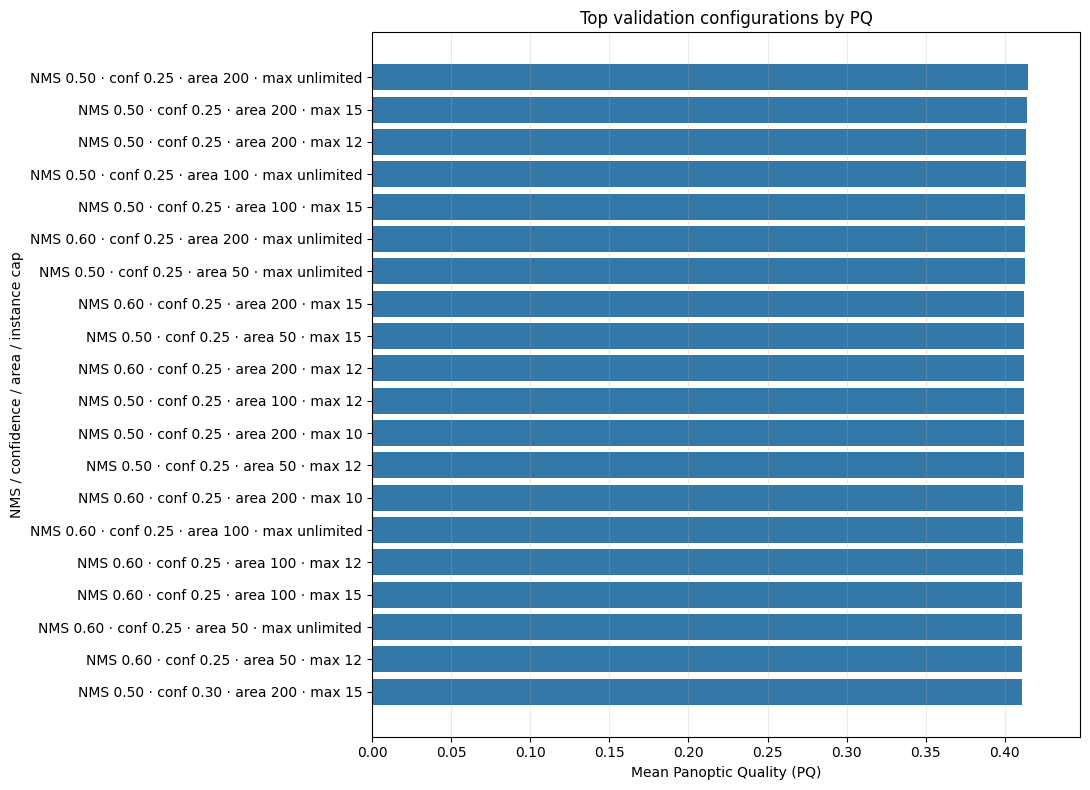

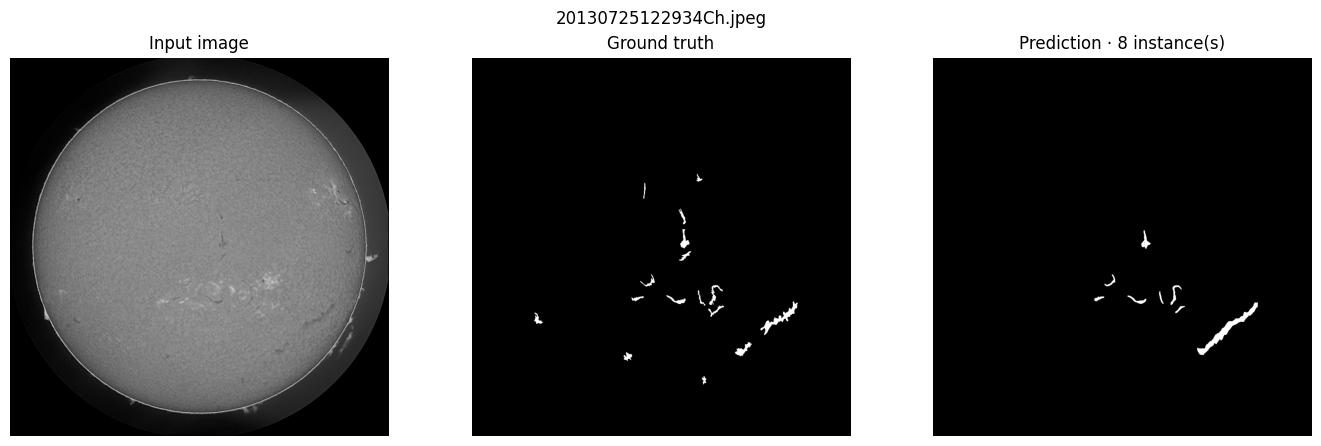

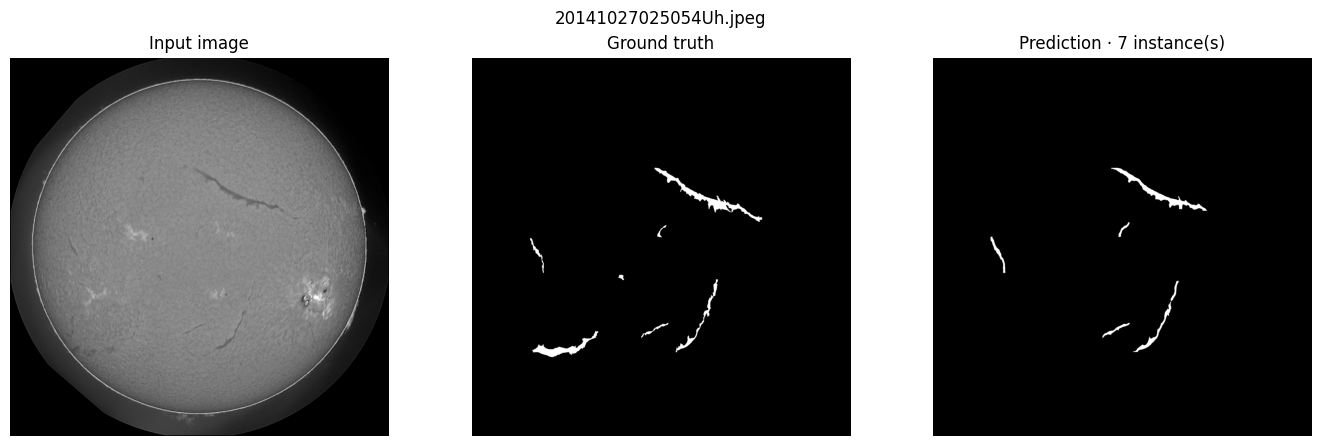

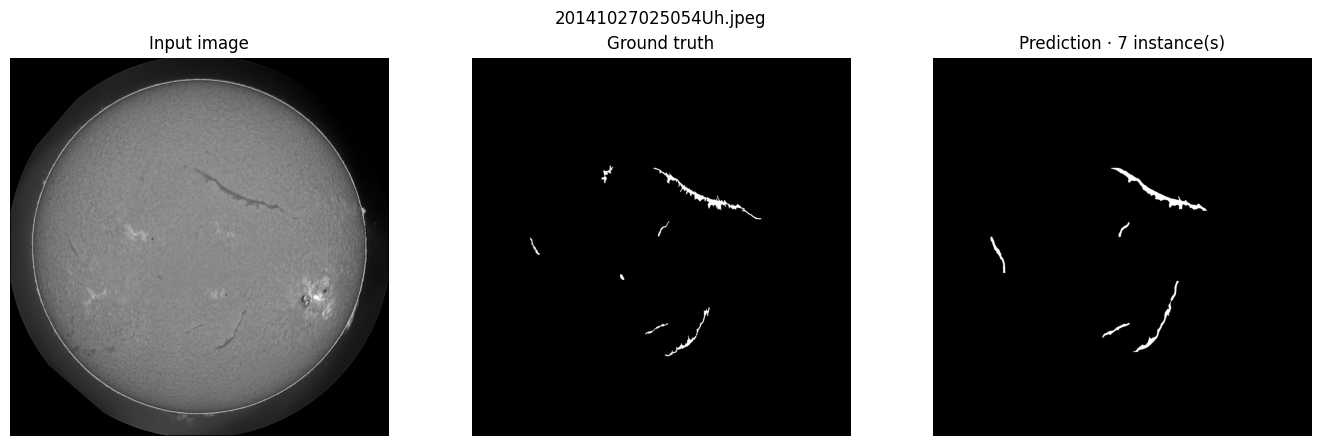

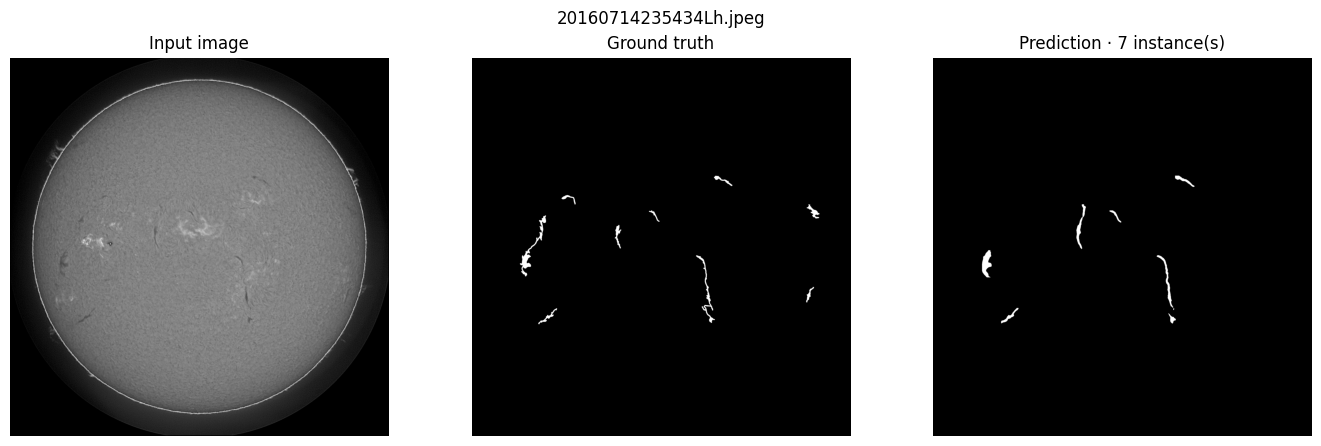

In [17]:
top_configs = threshold_summary.head(20).copy()
top_configs["configuration"] = top_configs.apply(
    lambda row: (
        f"NMS {row['NMS IoU']:.2f} · conf {row['confidence']:.2f} · "
        f"area {int(row['Minimum exclusive area'])} · "
        f"max {row['Maximum instances']}"
    ),
    axis=1,
)
top_configs = top_configs.sort_values("PQ", ascending=True)

fig, axis = plt.subplots(figsize=(11, 8))
axis.barh(top_configs["configuration"], top_configs["PQ"], color="#3478a8")
axis.set(
    title="Top validation configurations by PQ",
    xlabel="Mean Panoptic Quality (PQ)",
    ylabel="NMS / confidence / area / instance cap",
    xlim=(0, min(1.0, max(0.1, float(top_configs["PQ"].max()) * 1.08))),
)
axis.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

for example in validation_examples:
    image = example["image"]
    target = example["target"]
    instances = example["instances"]

    selected = select_final_prediction_instances(
        instances,
        confidence_threshold=BEST_CONFIDENCE,
        min_area=BEST_MIN_INSTANCE_AREA,
        max_instances=BEST_MAX_INSTANCES,
    )
    prediction = instances_to_union(selected, shape=target.shape)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
    axes[0].imshow(image, cmap="gray")
    axes[0].set_title("Input image")
    axes[1].imshow(target, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Ground truth")
    axes[2].imshow(prediction, cmap="gray", vmin=0, vmax=1)
    axes[2].set_title(f"Prediction · {len(selected)} instance(s)")

    for axis in axes:
        axis.axis("off")

    fig.suptitle(example["file_name"])
    fig.tight_layout()
    plt.show()


## 12. Display a labeled prediction on an unseen test image

This image is used only for inference and visualization. Test ground truth is not accessed.


Displaying labeled prediction for test image: 20110120105534Ch.jpeg


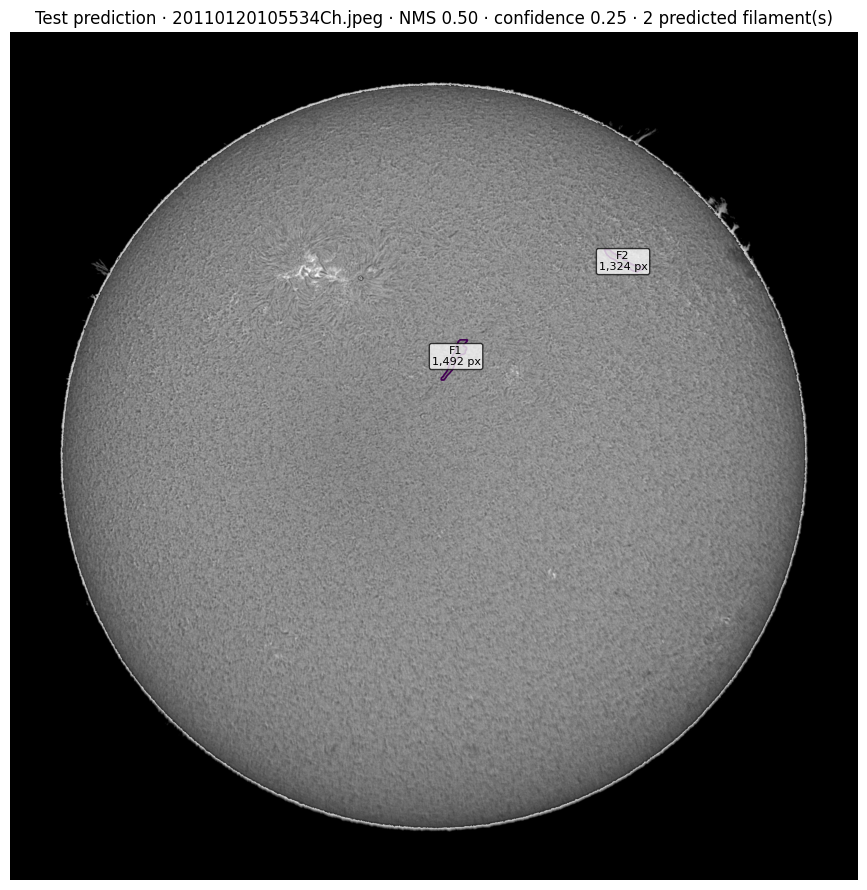

In [18]:
def plot_labeled_prediction(image, instances, title):
    selected = select_final_prediction_instances(
        instances,
        confidence_threshold=BEST_CONFIDENCE,
        min_area=BEST_MIN_INSTANCE_AREA,
        max_instances=BEST_MAX_INSTANCES,
    )

    fig, axis = plt.subplots(figsize=(9, 9))
    axis.imshow(image, cmap="gray")

    for filament_index, instance in enumerate(selected, start=1):
        component = instance["mask"]
        axis.contour(component.astype(np.uint8), levels=[0.5], linewidths=1.2)
        moments = cv2.moments(component.astype(np.uint8))

        if moments["m00"]:
            center_x = moments["m10"] / moments["m00"]
            center_y = moments["m01"] / moments["m00"]
        else:
            ys, xs = np.where(component)
            center_x, center_y = xs.mean(), ys.mean()

        area = int(component.sum())
        axis.text(
            center_x, center_y, f"F{filament_index}\n{area:,} px",
            fontsize=8, ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.75),
        )

    axis.set_title(f"{title} · {len(selected)} predicted filament(s)")
    axis.axis("off")
    fig.tight_layout()
    plt.show()


test_paths = get_test_image_paths()
if not test_paths:
    raise FileNotFoundError("No test images were found.")

test_path = test_paths[0]
test_image = cv2.imread(str(test_path), cv2.IMREAD_GRAYSCALE)
if test_image is None:
    raise OSError(f"Could not read test image: {test_path}")

test_instances = predict_instances(
    test_image,
    min_confidence=BEST_CONFIDENCE,
    nms_iou=BEST_NMS_IOU,
)
print(f"Displaying labeled prediction for test image: {test_path.name}")
plot_labeled_prediction(
    test_image,
    test_instances,
    (
        f"Test prediction · {test_path.name} · NMS {BEST_NMS_IOU:.2f} "
        f"· confidence {BEST_CONFIDENCE:.2f}"
    ),
)


## 13. Experiment summary

### Main outputs

- yolo_filament_dataset_polygon_direct/ — isolated YOLO labels and linked images
- yolo_runs/yolo26s_polygon_direct_exclusive_instances/weights/best.pt — experiment checkpoint
- solar_filament_yolo26s_polygon_exclusive_submission.csv — validation-tuned submission
- solar_filament_yolo26s_polygon_exclusive_validation_metrics.csv — best validation summary
- solar_filament_yolo26s_polygon_exclusive_per_image_metrics.csv — per-image metrics for the selected configuration

### Controlled changes

| Area | Experiment setting |
|---|---|
| COCO conversion | Preserve original polygon vertices; do not rasterize labels |
| Prediction overlap | Confidence-ordered mutually-exclusive masks |
| Validation | Confidence 0.05–0.60, NMS IoU 0.50–0.90, area 5–200, cap 5–15 or unlimited |
| Model/training | Keep YOLO26s, 2048 full-frame input, and baseline augmentation fixed |

The next experiments (mask ratio 2 with reduced rotation, tiled inference, a larger model, and fold ensembling) should be evaluated separately after this first comparison.
